# Recalibración CO₂ v3 — datos crudos completos y filtrado offline sin retardo de fase

Esta versión rehace la recalibración de LAB016–021 desde `flow_sccm`, conserva los notebooks anteriores y escribe únicamente tablas independientes junto a este notebook. **Todas las figuras quedan en los outputs: ninguna se guarda en `results`.**

**Esta ejecución corrige el cambio de hora de Chile y elimina las exclusiones de la primera v3.** La respuesta a la nutrición se conserva en los datos y en el ajuste.

**Cambios frente a v2:** observaciones cada **10 minutos** en vez de una hora; CO₂ y temperatura de los backups **completos** de LAB019–021; Hampel centrado seguido de Butterworth adelante–atrás desde los datos crudos; temperatura suavizada y utilizada efectivamente tanto por la química como por el gas; horizontes auditados hasta CO₂ cercano a cero y última química. Los puntos del ajuste son medianas de ventanas de 10 minutos situadas en su centro; no se desplazan registros 40 minutos ni se ajusta un retardo empírico.

**Configuración principal fijada antes de ajustar:** CO₂ con Butterworth orden 3, τ=30 min, dos pasadas; temperatura con mediana de 1 min → mediana móvil centrada de 20 min → media móvil centrada de 45 min. Se contrastan τ=20 y 40 min y temperatura 30/60 min. No se elige un filtro por obtener el menor RMSE sobre su propia señal suavizada: se publican también errores frente a una referencia común derivada del raw sin Butterworth.

Los parámetros químicos `theta_full` y `theta_defaults` se mantienen fijos. La fuente principal conserva las ecuaciones de v2 y sus posibles limitaciones; las mezclas positivas se presentan al final como una prueba estructural aparte. **Entrenamiento principal: LAB019–021; transferencia: LAB016–018.** También se conserva el ajuste conjunto descriptivo y la transferencia inversa de v2, sin presentarlos como validación externa. LAB016–018 ya se ha inspeccionado: toda esta comparación es exploratoria.

La inicialización heredada de LAB016–018 sigue siendo X₀=0.39 g/L, Xd₀=0 y G₀+F₀=172.5 g/L. Las primeras muestras de biomasa a ~10–11.5 h contradicen parte del crecimiento predicho; se muestran explícitamente y no se convierten silenciosamente en mediciones a t=0. Esta tarea cambia el tratamiento de señales, no reestima esa inicialización ni las energías de activación químicas.

**Organización del código:** las funciones específicas están definidas en celdas de este SOURCE. El EXECUTED se obtiene ejecutándolo completo; no requiere los auxiliares Python retirados.

## Trazabilidad integrada, sin manifiestos externos

Los registros de entrada, configuración, parámetros y verificaciones se construyen en las mismas celdas del análisis y se muestran al final del EXECUTED. Ya no se escriben manifiestos JSON externos. Los metadatos `traceability_archive` del SOURCE conservan los registros anteriores como archivo histórico (sus fechas y hashes de código corresponden a aquella ejecución).

In [1]:
from pathlib import Path
from datetime import datetime
import ast, json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display, Markdown
%matplotlib inline

ROOT=Path.cwd().resolve()
while ROOT.name!='pyomo-doe' and ROOT.parent!=ROOT:ROOT=ROOT.parent
assert ROOT.name=='pyomo-doe'
ND=ROOT/'fermentation_model/laboratory_2026/notebooks/diagnostics'
sys.path.insert(0,str(ND))
from copy import deepcopy
from IPython.display import JSON
TRACEABILITY = {}
def record_trace(label, payload):
    TRACEABILITY[label] = json.loads(json.dumps(payload), parse_constant=lambda token: None)

### Base de simulación y capa de CO₂

La base necesaria está incluida en este notebook: no se importa código del notebook de búsqueda ni un auxiliar externo.

In [2]:
"""Local, reproducible experiments for the CO2 v2 follow-up notebook.

Reads v2 data/initials, but never executes or writes the original notebook.
Chemical integration uses the shared official RHS. Experimental gas sources
are local to this module; no production equation or parameter file is changed.
"""

import ast
import hashlib
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import least_squares

TRAIN = ("LAB019", "LAB020", "LAB021")
HOLDOUT = ("LAB016", "LAB017", "LAB018")
GAS_NAMES = ("kCO2_release_h", "CO2sat_scale", "matrix_gain")
GAS_BOUNDS = ((.03, 25.), (.35, 2.5), (.1, 20.))
CHEM_COLUMNS = dict(N="YAN_mg_l", G="G_g_l", F="F_g_l", GF="GF_g_l", E="E_g_l", Gly="Gly_g_l")


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def local_lfs_content(path, root):
    """Read an already cached LFS object without hydrating/mutating the worktree."""
    with open(path, "rb") as handle:
        head = handle.read(200)
    if not head.startswith(b"version https://git-lfs.github.com/spec/v1"):
        return path
    lines = head.decode("ascii").splitlines()
    oid = next(line.split("sha256:", 1)[1] for line in lines if line.startswith("oid "))
    content = Path(root) / ".git/lfs/objects" / oid[:2] / oid[2:4] / oid
    if not content.is_file():
        raise FileNotFoundError(f"Required LFS object is absent locally: {oid}")
    assert sha256(content) == oid
    return content


def release_forward(c, p, max_step=None):
    """Conservative implicit reservoir, identical to v2 (positive root)."""
    k, scale, gain = (p[n] for n in GAS_NAMES)
    source, dt = c["source"], c["dt"]
    sat = c["sat_base"] * scale
    cd, out = np.zeros(len(source)), np.zeros(len(source))
    for i in range(1, len(source)):
        subdivisions = 1 if max_step is None else int(np.ceil(dt[i-1] / max_step))
        step = dt[i-1] / subdivisions
        inventory, released = cd[i-1], 0.
        for _ in range(subdivisions):
            a = inventory + step * source[i-1]
            aa = 1. + step * k
            b = sat[i] * (1. + .05 * step * k) - a
            root = np.sqrt(b*b + 4.*aa*a*sat[i])
            new = 2.*a*sat[i]/(root+b) if b >= 0. else (root-b)/(2.*aa)
            released += a - new
            inventory = new
        cd[i], out[i] = inventory, released/dt[i-1]
    return gain*out, cd, out


def features(t, y):
    t, y = np.asarray(t), np.asarray(y)
    peak = int(np.argmax(y))
    def run(mask, start=0):
        for i in range(max(2, start), len(t)):
            if mask[i-2:i+1].all() and np.allclose(np.diff(t[i-2:i+1]), 1.):
                return float(t[i])
        return np.nan
    return dict(peak_h=float(t[peak]), peak=float(y[peak]),
                onset_h=run(y >= .05), fall_h=run(y < .05, peak+2))


class Search:
    def __getstate__(self):
        return {k: v for k, v in self.__dict__.items() if k not in ("base", "joint", "cross", "gas")}

    def __setstate__(self, state):
        self.__dict__.update(state)
        from shared import run_new_must_glycerol_estimability_doe as base
        from shared import run_secondary_joint_campaign_doe as joint
        from laboratory_2026 import run_co2_matrix_cross_validation_2026 as cross
        import _post_activity_prediction as gas
        self.base, self.joint, self.cross, self.gas = base, joint, cross, gas

    def __init__(self, root):
        self.root = Path(root)
        self.fm = self.root / "fermentation_model"
        self.lab = self.fm / "laboratory_2026"
        for path in (self.fm, self.lab, self.fm / "pilot_2025", self.lab / "notebooks/EKF"):
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))
        from shared import run_new_must_glycerol_estimability_doe as base
        from shared import run_secondary_joint_campaign_doe as joint
        from laboratory_2026 import run_co2_matrix_cross_validation_2026 as cross
        import _post_activity_prediction as gas
        self.base, self.joint, self.cross, self.gas = base, joint, cross, gas
        self.v2 = self.lab / "results/co2_lab016_021_recalibration_v2"
        self.inputs = []
        def read(name):
            path = self.v2 / name
            self.inputs.append(path)
            return pd.read_csv(path)
        self.manifest = json.loads((self.v2 / "manifest.json").read_text(encoding="utf-8"))
        self.inputs.append(self.v2 / "manifest.json")
        self.thetas = self.manifest["theta_fixed"]
        self.old = {**self.manifest["old_gas_start"],
                    "activation_start_g_l": 2., "activation_width_g_l": 8.}
        self.initials = read("initial_conditions.csv").set_index("lab")
        self.obs = read("observations.csv")
        self.chem = read("chemistry_observations_corrected_YAN.csv")
        self.density = read("density_sugar_comparison/density_sugar_points.csv")
        self.biomass = read("biomass_lab016_018.csv")
        self.previous_parameters = read("parameters.csv")
        self.previous_gas = read("gas_trajectories.csv")
        self.previous_chemistry = read("chemistry_trajectories.csv")
        self.previous_transfer = read("transfer_metrics.csv")
        self.batches = {}
        recent_path = self.fm / "data/mem2026/LAB019-021/backup_global_temperatura_completo.csv"
        self.inputs.append(recent_path)
        recent_path = local_lfs_content(recent_path, self.root)
        self.inputs.append(recent_path)
        pieces = []
        t0 = pd.Timestamp("2026-09-21 17:00:00")
        for chunk in pd.read_csv(recent_path, usecols=["timestamp", "fermentador", "T"], chunksize=400000):
            ts = pd.to_datetime(chunk.timestamp, errors="coerce")
            keep = ts.between(t0-pd.Timedelta(hours=1), t0+pd.Timedelta(hours=167))
            if keep.any():
                d = chunk.loc[keep].copy()
                d["t_h"] = (ts[keep]-t0).dt.total_seconds()/3600.
                pieces.append(d)
        recent_temp = pd.concat(pieces, ignore_index=True)
        import openpyxl  # already required by the repository
        book = self.fm / "data/mem2026/LAB016-018/LAB016-018-offline-measurements.xlsx"
        self.inputs.append(book)
        ini_sheet = pd.read_excel(book, sheet_name="CondicionesIniciales").set_index("CodigoLab")
        for lab in HOLDOUT + TRAIN:
            row = self.initials.loc[lab]
            events = ast.literal_eval(row.N_events)
            horizon = float(row.horizon_h)
            time = np.unique(np.r_[np.arange(0., horizon, .25), horizon, [t for t, _ in events]])
            if lab in HOLDOUT:
                filename = dict(LAB016="Temp_F1_LAB016.csv", LAB017="Temp_F2_LAB017.csv", LAB018="Temp_F3._LAB018.csv")[lab]
                path = self.fm / "data/mem2026/LAB016-018" / filename
                self.inputs.append(path)
                temp = pd.read_csv(path, parse_dates=["timestamp"])
                initial = ini_sheet.loc[lab]
                clock = initial.Hora if hasattr(initial.Hora, "hour") else pd.to_datetime(str(initial.Hora)).time()
                start = pd.Timestamp.combine(pd.Timestamp(initial.Fecha).date(), clock)
                temp["t_h"] = (temp.timestamp-start).dt.total_seconds()/3600.
            else:
                fermenter = dict(zip(TRAIN, ("F1", "F2", "F3")))[lab]
                temp = recent_temp[recent_temp.fermentador.eq(fermenter)].copy()
            temp = temp.sort_values("t_h")
            self.batches[lab] = base.BatchData(
                medium="natural", batch=lab, time=time,
                temperature_c=np.interp(time, temp.t_h, temp["T"]),
                initials={s: float(row[s]) for s in base.STATE_NAMES},
                pulses={**{s: () for s in base.INPUT_CHANNELS}, "N": events},
                observations={s: np.full(len(time), np.nan) for s in base.STATE_NAMES})
        assert set(self.obs.lab) == set(TRAIN + HOLDOUT)
        self.inputs += [Path(m.__file__) for m in (base, joint, cross, gas)]
        self.inputs += list((self.lab / "notebooks/diagnostics").glob("co2_lab016_021_recalibration_v2.*.ipynb"))
        # Snapshot the entire previous results tree, including prior figure files.
        self.protected = {str(p.relative_to(self.root)): sha256(p)
                          for p in set(self.inputs) | {p for p in self.v2.rglob("*") if p.is_file()}}
        self.cores, self.cache, self.theta_by_case = {}, {}, {}
        self.runs = []

    def prepare(self, name, theta, labs=TRAIN):
        self.theta_by_case[name] = theta.copy()
        for lab in labs:
            if (name, lab) in self.cache:
                continue
            bt = self.batches[lab]
            core = self.gas.integrate_core(bt, theta, bt.time)
            core0 = self.gas.integrate_core(replace(bt, pulses={**bt.pulses, "N": ()}), theta, bt.time)
            core["GF"] = core.G + core.F
            self.cores[name, lab] = core
            time = bt.time
            events = bt.pulses["N"]
            ramp, multiplier = self.histories(time, events, self.old)
            consumed = core.GF.iloc[0]-core.GF.to_numpy()
            z = np.clip((consumed-2.)/8., 0., 1.)
            gate = z*z*(3.-2.*z)
            ini = bt.initials
            oxygen0 = self.old["O2_initial_scale"]*self.cross.co2_model.o2_saturation_mg_l(
                bt.temperature_c[0], ini["E"], ini["G"], ini["F"], 1.)
            ref = self.gas.finish(bt, theta, core, core0, self.old, gate, ramp, multiplier, 0., oxygen0)
            qn, q0 = self.gas.production(theta, bt, core), self.gas.production(theta, bt, core0)
            d = self.obs[self.obs.lab.eq(lab)].sort_values("t_h")
            idx = np.searchsorted(time, d.t_h.to_numpy())-1
            w = (d.t_h.to_numpy()-time[idx]) / (time[idx+1]-time[idx])
            phi = .75**2/(.75**2+ref.O2.to_numpy()**2)
            self.cache[name, lab] = dict(
                time=time, dt=np.diff(time), source=ref.qprod.to_numpy(),
                sat_base=ref.csat.to_numpy()/self.old["CO2sat_scale"],
                qn=qn, q0=q0, ramp=ramp, multiplier=multiplier,
                gate=gate, fferm=.08+.92*phi, obs=d, idx=idx, w=w,
                events=events, core=core, reference=ref, core0_X=core0.X.to_numpy(),
                oxygen0=oxygen0, sugar_consumed=consumed)

    @staticmethod
    def histories(time, events, p):
        ramp = np.clip((time-events[0][0])/p["pulse_t_rise_h"], 0., 1.) if events else np.zeros(len(time))
        mult = np.ones(len(time))
        tr, td = p["tau_rise_h"], p["tau_decay_h"]
        up = tr*np.log1p(td/tr)
        peak = -np.expm1(-up/tr)*np.exp(-up/td)
        for event, dose in events:
            u = np.maximum(time-event, 0.)
            mult += p["A"]*dose/p["N_ref_g_l"]*(-np.expm1(-u/tr))*np.exp(-u/td)/peak
        return ramp, mult

    def source_cache(self, case, lab, p, mode="v2"):
        c = self.cache[case, lab]
        if mode == "v2":
            return c
        ramp, mult = self.histories(c["time"], c["events"], p)
        b = p["pulse_activity_gain"]
        if mode in ("v2_free", "v2_gate"):
            raw = (1.+(b-1.)*ramp)*c["q0"]+ramp*(c["qn"]-c["q0"])
        elif mode in ("positive_mix", "positive_gate"):
            # Nonnegative interpolation: at r=1, source is b*qn, not qn-(1-b)*q0.
            raw = (1.-ramp)*c["q0"]+b*ramp*c["qn"]
        elif mode == "chemical":
            raw = c["qn"]
        else:
            raise ValueError(mode)
        gate = c["gate"]
        if mode in ("v2_gate", "positive_gate"):
            z = np.clip((c["sugar_consumed"]-p["activation_start_g_l"])/p["activation_width_g_l"], 0., 1.)
            gate = z*z*(3.-2.*z)
        # The oxygen parameters remain fixed, but its state follows the changed
        # biomass interpolation when the pulse ramp duration is recalibrated.
        fferm = c["fferm"]
        if not np.array_equal(ramp, c["ramp"]):
            biomass = np.maximum(c["core0_X"]+ramp*(c["core"].X.to_numpy()-c["core0_X"]), 0.)
            oxygen = np.zeros(len(ramp))
            oxygen[0] = c["oxygen0"]
            for i, dt in enumerate(c["dt"]):
                uptake = p["O2_qmax_mg_gdw_h"]*biomass[i]*oxygen[i]/(.25+oxygen[i])
                oxygen[i+1] = max(oxygen[i]-dt*uptake, 0.)
            fferm = .08+.92*.75**2/(.75**2+oxygen**2)
        return {**c, "gate": gate, "source": gate*fferm*mult*np.maximum(raw, 0.)}

    def curve(self, case, lab, params, mode="v2", max_step=None):
        c = self.source_cache(case, lab, params, mode)
        pred, cd, qgas = release_forward(c, params, max_step)
        return pd.DataFrame(dict(t_h=c["time"], CO2=pred, Cd=cd, qgas=qgas,
                                 qprod=c["source"], qn=c["qn"], q0=c["q0"],
                                 ramp=self.histories(c["time"], c["events"], params)[0],
                                 gate=c["gate"]))

    def fit(self, case, labs=TRAIN, mode="v2", starts=2, initial=None, max_nfev=100):
        assert set(labs).issubset(TRAIN), "Holdout cannot enter optimization"
        extra = {"v2_free": ("pulse_activity_gain", "pulse_t_rise_h"),
                 "positive_mix": ("pulse_activity_gain", "pulse_t_rise_h"),
                 "v2_gate": ("activation_start_g_l", "activation_width_g_l"),
                 "positive_gate": ("pulse_activity_gain", "pulse_t_rise_h", "activation_start_g_l", "activation_width_g_l"),
                 "chemical": ("A",)}.get(mode, ())
        names = GAS_NAMES + extra
        bounds = GAS_BOUNDS + tuple({"pulse_activity_gain": (.05, 1.5),
                                     "pulse_t_rise_h": (6., 120.), "A": (.001, 1.),
                                     "activation_start_g_l": (.2, 30.),
                                     "activation_width_g_l": (2., 40.)}[n] for n in extra)
        lo, hi = np.log(np.array(bounds).T)
        def residual(x):
            p = {**self.old, **dict(zip(names, np.exp(x)))}
            parts = []
            for lab in labs:
                c = self.source_cache(case, lab, p, mode)
                pred = release_forward(c, p)[0]
                ix, w = c["idx"], c["w"]
                sampled = pred[ix]*(1.-w)+pred[ix+1]*w
                y = c["obs"].y.to_numpy()
                e = np.where(y >= .05, sampled-y, np.maximum(sampled-.05, 0.))
                parts.append(e/np.sqrt(len(e)))
            return np.concatenate(parts)
        seeds = [initial or {**self.old, "kCO2_release_h": 2., "CO2sat_scale": 1., "matrix_gain": 1.}]
        if starts > 1:
            seeds.append({**self.old, "kCO2_release_h": .15, "CO2sat_scale": 2.4, "matrix_gain": 1.})
        solutions = []
        for i, seed in enumerate(seeds):
            seed = {**self.old, **seed}
            x0 = np.clip(np.log([seed[n] for n in names]), lo+1e-9, hi-1e-9)
            sol = least_squares(residual, x0, bounds=(lo, hi), max_nfev=max_nfev,
                                ftol=2e-7, xtol=2e-7, gtol=2e-7)
            self.runs.append(dict(case=case, mode=mode, labs=",".join(labs), start=i,
                                  objective=float(sol.fun@sol.fun), success=bool(sol.success),
                                  nfev=sol.nfev, message=sol.message))
            solutions.append(sol)
        best = min(solutions, key=lambda s: s.fun@s.fun)
        p = {**self.old, **dict(zip(names, np.exp(best.x)))}
        singular = np.linalg.svd(best.jac, compute_uv=False)
        return dict(case=case, mode=mode, params=p, objective=float(best.fun@best.fun),
                    success=bool(best.success), nfev=best.nfev,
                    jacobian_ratio=float(singular[-1]/singular[0]),
                    active_bounds=",".join(n for n, x, a, b in zip(names, best.x, lo, hi)
                                           if min(x-a, b-x) < .005))

    def chemistry_metrics(self, case, labs=TRAIN):
        rows = []
        for lab in labs:
            cr = self.cores[case, lab]
            d = self.chem[self.chem.lab.eq(lab) & ~self.chem.is_NUT & self.chem.t_h.gt(0.)]
            for ch, col in CHEM_COLUMNS.items():
                pts = d[["t_h", col]].dropna()
                if not len(pts):
                    continue
                error = np.interp(pts.t_h, cr.index, cr[ch]*(1000. if ch == "N" else 1.))-pts[col].to_numpy()
                rows.append(dict(case=case, lab=lab, channel=ch, n=len(pts),
                                 RMSE=float(np.sqrt(np.mean(error**2))), bias=float(error.mean())))
        return pd.DataFrame(rows)

    def gas_metrics(self, case, params, mode="v2", labs=TRAIN):
        rows = []
        for lab in labs:
            c = self.cache[case, lab]
            curve = self.curve(case, lab, params, mode)
            d = c["obs"]
            pred = np.interp(d.t_h, curve.t_h, curve.CO2)
            error = pred-d.y.to_numpy()
            observed, predicted = features(d.t_h, d.y), features(d.t_h, pred)
            late = d.t_h.to_numpy() >= 100.
            post = d.t_h.to_numpy() >= observed["peak_h"]
            for window, mask in (("all", np.ones(len(d), bool)), ("after_peak", post), ("after_100h", late)):
                rows.append(dict(case=case, mode=mode, lab=lab, window=window, n=int(mask.sum()),
                    RMSE=float(np.sqrt(np.mean(error[mask]**2))), MAE=float(np.mean(abs(error[mask]))),
                    bias=float(error[mask].mean()), **predicted,
                    observed_fall_h=observed["fall_h"], observed_onset_h=observed["onset_h"],
                    max_decline_5h=float(np.max(np.interp(curve.t_h+5., curve.t_h, -curve.CO2)+curve.CO2))))
        return pd.DataFrame(rows)

    def checks(self, case, params, mode="v2", labs=TRAIN+HOLDOUT):
        rows = []
        for lab in labs:
            c = self.source_cache(case, lab, params, mode)
            curve = self.curve(case, lab, params, mode)
            balance = np.max(abs(np.diff(curve.Cd)-c["dt"]*(c["source"][:-1]-curve.qgas.to_numpy()[1:])))
            cr = self.cores[case, lab]
            theta = self.theta_by_case[case]
            dose = np.array([sum(d for t, d in c["events"] if t < ti) for ti in c["time"]])
            inventory = cr.N+theta["qN"]/theta["mu0"]*(cr.X+cr.Xd)-dose
            n_error = np.max(abs(inventory-inventory.iloc[0]))
            fine = self.curve(case, lab, params, mode, max_step=.0625)
            refinement = np.max(abs(curve.CO2-fine.CO2))
            assert balance < 1e-10 and n_error < 2e-6
            assert curve[["CO2", "Cd", "qprod"]].min().min() >= -1e-12
            rows.append(dict(case=case, mode=mode, lab=lab, balance=balance,
                             nitrogen_balance=n_error, refinement_max_CO2=refinement))
        return pd.DataFrame(rows)

    def verify_protected(self):
        assert all(sha256(self.root/p) == h for p, h in self.protected.items())
        return len(self.protected)

### Filtrado offline, reloj de Chile y recalibración v3

Se conserva la implementación corregida, incluidos el cambio de hora y el soporte de nutrición.

In [3]:
"""Offline, zero-phase preprocessing and CO2 recalibration for LAB016--021.

Only local diagnostic artifacts are written by the accompanying notebook.
GUI scripts are parsed for parameters; hardware/UI code is never imported.
"""

import ast
import json
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal
from scipy.optimize import least_squares, minimize_scalar


LABS = tuple(f"LAB{i:03}" for i in range(16, 22))
FILTERS = {"offline_20min": 1200., "offline_30min": 1800., "offline_40min": 2400.}
PRIMARY = "offline_30min"
OBS_STEP_H = 1. / 6.
LOD = .05
QUIET = .02
FACTOR = 44.0095 * 60. * .74 / (1000. * 24.16 * 2.)
LOCAL_ZONE = "America/Santiago"


def local_to_utc(values):
    """Interpret logger/worksheet civil times, rejecting ambiguous/invalid times."""
    return pd.DatetimeIndex(pd.to_datetime(values)).tz_localize(
        LOCAL_ZONE, ambiguous="raise", nonexistent="raise").tz_convert("UTC")


def elapsed_civil_hours(hours, origin_local):
    """Convert legacy naive-clock offsets, not actual elapsed durations, to UTC."""
    wall = origin_local + pd.to_timedelta(np.asarray(hours, float), unit="h")
    return (local_to_utc(wall)-local_to_utc([origin_local])[0]).total_seconds()/3600.


def gui_constants(path):
    wanted = {"W_SPIKE_SECONDS", "K", "MIN_ABS_SPIKE", "TAU_SECONDS", "BUTTER_ORDER"}
    constants = {}
    for node in ast.parse(Path(path).read_text(encoding="utf-8-sig")).body:
        if isinstance(node, ast.Assign):
            for target in node.targets:
                if isinstance(target, ast.Name) and target.id in wanted:
                    constants[target.id] = ast.literal_eval(node.value)
    assert set(constants) == wanted, constants
    return constants


def centered_hampel(values, dt_s, window_s=120., k=3.5, floor=.5):
    """Exact median/MAD of the same centered odd window, reflection at edges."""
    x = np.asarray(values, float)
    assert np.isfinite(x).all()
    half = max(1, int(round(window_s / (2. * dt_s))))
    padded = np.pad(x, (half, half), mode="reflect")
    windows = sliding_window_view(padded, 2 * half + 1)
    med = np.median(windows, axis=1)
    mad = np.median(abs(windows - med[:, None]), axis=1)
    flag = abs(x-med) > np.maximum(k * 1.4826 * mad, floor)
    return np.where(flag, med, x), flag


def runs(mask):
    edges = np.diff(np.r_[False, np.asarray(mask, bool), False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def fill_short_gaps(series, max_samples):
    result = series.copy()
    candidate = series.interpolate(method="time", limit_area="inside")
    for a, b in runs(series.isna().to_numpy()):
        if b-a <= max_samples and a > 0 and b < len(series):
            result.iloc[a:b] = candidate.iloc[a:b]
    return result


def butter_sos(tau_s, dt_s, order=3):
    cutoff = 1. / (2. * np.pi * tau_s)
    return signal.butter(order, cutoff, fs=1. / dt_s, output="sos")


def zero_phase(values, tau_s, dt_s):
    # The default SciPy padding is too short for this very low cutoff.
    padlen = min(int(np.ceil(6. * tau_s / dt_s)), len(values)-2)
    assert padlen > 12 and len(values) > 24
    return signal.sosfiltfilt(butter_sos(tau_s, dt_s), values, padtype="odd", padlen=padlen)


def read_window(path, root, columns, start, end=None):
    content = local_lfs_content(path, root)
    pieces = []
    for chunk in pd.read_csv(content, usecols=columns, chunksize=400000, low_memory=False):
        stamp = pd.to_datetime(chunk.timestamp, errors="coerce")
        keep = stamp.ge(start)
        if end is not None:
            keep &= stamp.le(end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part["timestamp"] = stamp[keep]
            pieces.append(part)
    if not pieces:
        raise ValueError(f"No data in requested window: {path}")
    return pd.concat(pieces, ignore_index=True), content


def old_artifact_windows(raw, temp, t0):
    """Same raw excursion rule and 90-min conservative recovery used by v2."""
    state = pd.to_numeric(temp.nutricion_activa, errors="raise").astype(int)
    rising = np.flatnonzero((state.eq(1) & ~state.shift(fill_value=0).eq(1)).to_numpy())
    falling = np.flatnonzero((state.eq(0) & state.shift(fill_value=0).eq(1)).to_numpy())
    raw = raw.sort_values("timestamp")
    rtime = (raw.timestamp-t0).dt.total_seconds().to_numpy() / 3600.
    values = raw.flow_sccm.to_numpy(float)
    rows = []
    for a in rising:
        after = falling[falling > a]
        begin = (temp.timestamp.iloc[a]-t0).total_seconds()/3600.
        finish = (temp.timestamp.iloc[after[0]]-t0).total_seconds()/3600. if len(after) else (temp.timestamp.iloc[-1]-t0).total_seconds()/3600.
        pre = values[(rtime >= begin-1./3.) & (rtime < begin)]
        event_idx = np.flatnonzero((rtime >= begin) & (rtime <= finish+1./30.))
        if len(pre) < 3 or not len(event_idx):
            continue
        center = np.median(pre)
        threshold = max(3.5*1.4826*np.median(abs(pre-center)), .5)
        crossed = event_idx[abs(values[event_idx]-center) > threshold]
        if len(crossed):
            rows.append(dict(start_h=float(rtime[crossed[0]]), end_h=float(finish+1.5),
                             pump_start_h=begin, pump_end_h=finish, raw_threshold_sccm=threshold))
    return rows


class RecalibrationV3(Search):
    def __init__(self, root):
        super().__init__(root)
        self.v2_initials = self.initials.copy()
        self.v2_obs = self.obs.copy()
        self.gui_paths = [self.fm/"context/codigo_GUI"/name for name in
                          ("NEW_GUI_filtrado_vFINAL.py", "NEW_GUI_filtrado_vCTORREALBA_EZO_USB.py")]
        self.gui = gui_constants(self.gui_paths[0])
        assert self.gui == gui_constants(self.gui_paths[1])
        assert self.gui == dict(W_SPIKE_SECONDS=120., K=3.5, MIN_ABS_SPIKE=.5,
                                TAU_SECONDS=1200., BUTTER_ORDER=3)
        self.raw_co2, self.raw_temperature, self.t0, self.artifacts = {}, {}, {}, {}
        self.dense, self.temperature, self.observations = {}, {}, {}
        self.filter_audit, self.coverage_rows, self.temp_audit = [], [], []
        self.fit_runs, self.fit_table, self.v3_fits = [], [], {}
        self.saved_core_contexts = {}
        self.clock_audit, self.elapsed_audit, self.nutrition_events = [], [], []
        old_dir = self.fm/"data/mem2026/LAB016-018"
        book_path = old_dir/"LAB016-018-offline-measurements.xlsx"
        sheet = pd.read_excel(book_path, sheet_name="CondicionesIniciales").set_index("CodigoLab")
        recent_dir = self.fm/"data/mem2026/LAB019-021"
        recent_t0 = pd.Timestamp("2026-09-21 17:00:00")
        recent_co2_path = recent_dir/"backup_global_co2_completo.csv"
        recent_temp_path = recent_dir/"backup_global_temperatura_completo.csv"
        # End is the actual end of each complete logger, not a preset 166/170 h.
        recent_co2, cpath = read_window(recent_co2_path, self.root,
            ["timestamp", "fermentador", "flow_sccm", "flow_filt_sccm", "status"], recent_t0-pd.Timedelta(hours=6))
        recent_temp, tpath = read_window(recent_temp_path, self.root,
            ["timestamp", "fermentador", "T", "SP", "nutricion_activa"], recent_t0-pd.Timedelta(hours=6))
        self.extra_inputs = self.gui_paths + [recent_co2_path, recent_temp_path, cpath, tpath,
            self.lab/"notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.ipynb",
            self.lab/"notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.executed.ipynb"]
        for i, lab in enumerate(LABS):
            fermenter = f"F{i%3+1}"
            if i < 3:
                row = sheet.loc[lab]
                clock = row.Hora if hasattr(row.Hora, "hour") else pd.to_datetime(str(row.Hora)).time()
                t0 = pd.Timestamp.combine(pd.Timestamp(row.Fecha).date(), clock)
                raw_path = old_dir/f"CO2_F{i+1}_{lab}.csv"
                filt_path = old_dir/f"CO2_FILT_F{i+1}_{lab}.csv"
                temp_path = old_dir/({0:"Temp_F1_LAB016.csv",1:"Temp_F2_LAB017.csv",2:"Temp_F3._LAB018.csv"}[i])
                raw = pd.read_csv(raw_path, parse_dates=["timestamp"])
                recorded = pd.read_csv(filt_path, parse_dates=["timestamp"])
                raw = raw.merge(recorded[["timestamp", "flow_filt_sccm"]], on="timestamp", how="left", validate="one_to_one")
                tmp = pd.read_csv(temp_path, parse_dates=["timestamp"])
                self.extra_inputs += [raw_path, filt_path, temp_path]
            else:
                t0 = recent_t0
                raw = recent_co2[recent_co2.fermentador.eq(fermenter)].copy()
                tmp = recent_temp[recent_temp.fermentador.eq(fermenter)].copy()
            origin_local = t0
            t0 = local_to_utc([origin_local])[0]
            for kind, frame in (("co2", raw), ("temperature", tmp)):
                wall = pd.DatetimeIndex(frame.timestamp)
                utc = local_to_utc(wall)
                local_dt = wall.to_series(index=np.arange(len(wall))).diff().dt.total_seconds().to_numpy()
                real_dt = utc.to_series(index=np.arange(len(utc))).diff().dt.total_seconds().to_numpy()
                jumps = np.flatnonzero(abs(local_dt-real_dt)>1.)
                for j in jumps:
                    self.clock_audit.append(dict(lab=lab,signal=kind,
                        previous_local=str(wall[j-1]),next_local=str(wall[j]),
                        previous_utc=str(utc[j-1]),next_utc=str(utc[j]),
                        civil_interval_seconds=float(local_dt[j]),elapsed_interval_seconds=float(real_dt[j])))
                frame["timestamp_local"] = frame.timestamp.astype(str)
                frame["timestamp"] = utc
            raw = raw[raw.timestamp.ge(t0-pd.Timedelta(hours=6))].sort_values("timestamp").copy()
            tmp = tmp[tmp.timestamp.ge(t0-pd.Timedelta(hours=6))].sort_values("timestamp").copy()
            assert raw.timestamp.is_unique and tmp.timestamp.is_unique
            raw["t_h"] = (raw.timestamp-t0).dt.total_seconds()/3600.
            tmp["t_h"] = (tmp.timestamp-t0).dt.total_seconds()/3600.
            self.t0[lab], self.raw_co2[lab], self.raw_temperature[lab] = t0, raw, tmp
            # Pump activation is nutrition, not evidence of a measurement artifact.
            # Keep its measured response; no bridges, recovery windows or guards.
            self.artifacts[lab] = []
            state = pd.to_numeric(tmp.nutricion_activa, errors="raise").eq(1)
            for a,b in runs(state):
                self.nutrition_events.append(dict(lab=lab,start_h=float(tmp.t_h.iloc[a]),
                    end_h=float(tmp.t_h.iloc[min(b,len(tmp)-1)]),excluded_from_fit=False))
            for name, frame in (("chemistry",self.chem),("density",self.density),
                                ("biomass",self.biomass),("previous_chemistry",self.previous_chemistry)):
                ids = frame.index[frame.lab.eq(lab)]
                if not len(ids):continue
                # t_h=0 may intentionally map a pre-inoculation sample to the
                # initial condition. Preserve that mapping and the measurement.
                old = frame.loc[ids,"t_h"].to_numpy(float)
                if name == "previous_chemistry":
                    # The legacy simulation includes artificial civil-clock
                    # grid points inside the skipped hour; they are not samples.
                    wall = origin_local+pd.to_timedelta(old,unit="h")
                    utc = pd.DatetimeIndex(wall).tz_localize(LOCAL_ZONE,
                        ambiguous="raise",nonexistent="NaT").tz_convert("UTC")
                    exists = ~utc.isna()
                    frame.drop(index=ids[~exists],inplace=True)
                    ids,old,utc = ids[exists],old[exists],utc[exists]
                    new = (utc-t0).total_seconds()/3600.
                else:
                    new = elapsed_civil_hours(old,origin_local)
                frame.loc[ids,"t_h"] = new
                for idx,before,after in zip(ids,old,new):
                    self.elapsed_audit.append(dict(lab=lab,table=name,row=int(idx),
                        civil_t_h=float(before),elapsed_t_h=float(after)))
            old_events = ast.literal_eval(self.initials.loc[lab,"N_events"])
            corrected_events = tuple((float(elapsed_civil_hours([h],origin_local)[0]),dose) for h,dose in old_events)
            self.initials.loc[lab,"N_events"] = repr(corrected_events)
            self.initials.loc[lab,"horizon_h"] = float(elapsed_civil_hours(
                [self.v2_initials.loc[lab,"horizon_h"]],origin_local)[0])
        protected = set(self.extra_inputs)
        for name in ("co2_lab016_021_recalibration", "co2_lab016_021_recalibration_v2"):
            protected.update(p for p in (self.lab/"results"/name).rglob("*") if p.is_file())
            protected.update((self.lab/"notebooks/diagnostics").glob(name+".*.ipynb"))
        protected.add(self.lab/"notebooks/diagnostics/co2_lab016_021_recalibration_v3.source.ipynb")
        self.protected.update({str(p.relative_to(self.root)):sha256(p) for p in protected})

    def process(self):
        for lab in LABS:
            self._process_temperature(lab)
            self._process_co2(lab)
        self.filter_audit = pd.DataFrame(self.filter_audit)
        self.temp_audit = pd.DataFrame(self.temp_audit)
        self._choose_horizons()
        self.coverage = pd.DataFrame(self.coverage_rows)
        # Use the same native ten-minute support for all smoothing sensitivities.
        for lab in LABS:
            dense = self.dense[lab]
            cut = self.horizons[lab]
            width = OBS_STEP_H
            bin_id = np.floor(dense.time_h/width+1e-10).astype(int)
            frame = dense.copy()
            valid = frame.valid_for_fit & frame.time_h.ge(0.) & frame.time_h.le(cut)
            frame["bin"] = bin_id
            agg = frame[valid].groupby("bin").agg(lo=("time_h", "min"),hi=("time_h", "max"),n=("time_h", "size"))
            dt = self.filter_blocks[lab][0]
            keep = (agg.hi-agg.lo >= .75*width) & agg.n.ge(.75*width*3600./dt) & (agg.index*width >= 0.) & ((agg.index+1)*width <= cut+1e-9)
            for a,b in self.fit_exclusions[lab]:
                keep &= ~((agg.index*width <= b)&((agg.index+1)*width >= a))
            bins = agg[keep].index
            for name in FILTERS:
                grouped = frame[valid].groupby("bin")[name].median().reindex(bins)
                points = pd.DataFrame(dict(lab=lab,bin=bins,t_h=(bins+.5)*width,y=grouped.to_numpy()))
                assert points.y.notna().all() and points.t_h.is_unique
                self.observations[name,lab] = points
        self.obs = pd.concat([self.observations[PRIMARY,lab] for lab in LABS],ignore_index=True)
        self.configure_temperature("reference_20_45")

    def _process_temperature(self, lab):
        raw = self.raw_temperature[lab]
        minute = raw.set_index("timestamp")[["T", "SP"]].resample("1min").median()
        minute["T"] = fill_short_gaps(minute["T"], 2)
        result = pd.DataFrame(index=minute.index)
        result["raw_1min"] = minute["T"]
        for name, med, mean in (("reference_20_45", "20min", "45min"), ("strong_30_60", "30min", "60min")):
            result[name] = np.nan
            for a,b in runs(minute["T"].notna()):
                segment = minute["T"].iloc[a:b]
                filtered = segment.rolling(med,center=True,min_periods=1).median().rolling(mean,center=True,min_periods=1).mean()
                result.iloc[a:b,result.columns.get_loc(name)] = filtered.to_numpy()
            valid = result[name].notna() & result.raw_1min.notna()
            self.temp_audit.append(dict(lab=lab,variant=name,raw_std_C=float(result.loc[valid,"raw_1min"].std()),
                filtered_std_C=float(result.loc[valid,name].std()),mean_change_C=float((result.loc[valid,name]-result.loc[valid,"raw_1min"]).mean()),
                max_change_C=float(abs(result.loc[valid,name]-result.loc[valid,"raw_1min"]).max())))
        result["SP"] = minute.SP
        result["time_h"] = (result.index-self.t0[lab]).total_seconds()/3600.
        self.temperature[lab] = result

    def _process_co2(self, lab):
        raw = self.raw_co2[lab]
        dt = float(raw.timestamp.diff().dt.total_seconds().median())
        assert 5. <= dt <= 30., (lab,dt)
        series = raw.set_index("timestamp")[["flow_sccm", "flow_filt_sccm"]].resample(pd.Timedelta(seconds=dt)).median()
        series.index += pd.Timedelta(seconds=dt/2.)
        series["flow_sccm"] = fill_short_gaps(series.flow_sccm, int(60./dt))
        time = (series.index-self.t0[lab]).total_seconds().to_numpy()/3600.
        clean = series.flow_sccm.copy()
        frame = pd.DataFrame(dict(time_h=time,raw_sccm=series.flow_sccm.to_numpy(),
            recorded_sccm=series.flow_filt_sccm.to_numpy(),clean_sccm=clean.to_numpy()),index=series.index)
        frame["despiked_sccm"],frame["hampel_spike"] = np.nan,False
        blocks = [(a,b) for a,b in runs(clean.notna()) if b-a > 100]
        for name in FILTERS:
            frame[name] = np.nan
        for a,b in blocks:
            despiked, flag = centered_hampel(clean.iloc[a:b].to_numpy(), dt)
            frame.iloc[a:b,frame.columns.get_loc("despiked_sccm")] = despiked
            frame.iloc[a:b,frame.columns.get_loc("hampel_spike")] = flag
            for name,tau in FILTERS.items():
                frame.iloc[a:b,frame.columns.get_loc(name)] = zero_phase(despiked,tau,dt)
        # One sensor-zero estimate, from the same raw-derived despiked baseline,
        # is shared by every smoothing variant. Nothing is subtracted from chemistry.
        baseline = (time >= 2.5) & (time <= 12.) & frame.despiked_sccm.notna().to_numpy()
        for event in self.artifacts[lab]:
            baseline &= ~((time >= event["start_h"]) & (time <= event["end_h"]))
        assert baseline.sum() > 20, lab
        zero = max(0.,float(frame.loc[baseline,"despiked_sccm"].quantile(.1)))
        self.fit_exclusions = getattr(self,"fit_exclusions",{})
        # Padding is a numerical extension only, never a fit exclusion margin.
        guard = 0.
        exclusions = []
        self.fit_exclusions[lab] = exclusions
        valid = frame[PRIMARY].notna().to_numpy()
        for name,tau in FILTERS.items():
            uncorrected = frame[name].to_numpy().copy()
            frame[name] = np.maximum(uncorrected-zero,0.)*FACTOR
            use = valid & (time >= 0.)
            peak = int(np.nanargmax(np.where(use,frame[name],np.nan)))
            self.filter_audit.append(dict(lab=lab,variant=name,tau_s=tau,order=3,passes=2,
                raw_dt_s=dt,zero_sccm=zero,n_raw=len(raw),n_grid=len(frame),
                n_hampel=int(frame.hampel_spike.sum()),n_fit_dense=int(use.sum()),
                peak_g_l_h=float(frame[name].iloc[peak]),peak_h=float(time[peak]),
                negative_before_clipping_fraction=float(np.nanmean(uncorrected < zero)),
                data_start_h=float(time[0]),data_end_h=float(time[-1]),guard_h=guard))
        frame["despiked"] = np.maximum(frame.despiked_sccm-zero,0.)*FACTOR
        frame["recorded"] = np.maximum(frame.recorded_sccm-float(pd.read_csv(self.v2/"sensor_audit.csv").set_index("lab").loc[lab,"zero_sccm"]),0.)*FACTOR
        frame["valid_for_fit"] = valid
        self.dense[lab] = frame
        self.filter_blocks = getattr(self,"filter_blocks",{})
        self.filter_blocks[lab] = (dt, blocks)

    def _choose_horizons(self):
        self.horizons = {}
        for lab in LABS:
            dense = self.dense[lab]
            time = dense.time_h.to_numpy()
            if lab in LABS[3:]:
                last_chem = float(self.chem[self.chem.lab.eq(lab)&~self.chem.is_NUT].t_h.max())
            else:
                last_chem = float(max(self.density[self.density.lab.eq(lab)].t_h.max(),
                                      self.biomass[self.biomass.lab.eq(lab)].t_h.max()))
            # Horizon is fixed by the primary observation preprocessing, never
            # by a fitted model. Any unresolved ending is explicitly censored.
            frame = dense[dense.time_h.ge(0.)&dense.valid_for_fit].copy()
            frame["bin"] = np.floor(frame.time_h/OBS_STEP_H).astype(int)
            ten = frame.groupby("bin")[PRIMARY].median()
            tt = (ten.index.to_numpy()+.5)*OBS_STEP_H
            last_active = float(tt[ten.to_numpy() >= LOD][-1]) if (ten>=LOD).any() else 0.
            quiet_end = np.nan
            for i in range(len(ten)-11):
                chunk = ten.iloc[i:i+12]
                if tt[i] >= last_active and np.all(np.diff(chunk.index)==1) and chunk.le(QUIET).all():
                    quiet_end = float((chunk.index[-1]+1)*OBS_STEP_H)
                    break
            available = min(float(dense.time_h.max()),float(self.raw_temperature[lab].t_h.max()))
            requested = max(last_chem,quiet_end) if np.isfinite(quiet_end) else available
            cut = min(requested,available)
            assert last_chem <= available+1e-6, (lab,last_chem,available)
            self.horizons[lab] = cut
            self.coverage_rows.append(dict(lab=lab,last_chemical_or_offline_h=last_chem,
                previous_v2_end_h=float(self.v2_initials.loc[lab,"horizon_h"]),
                raw_co2_end_h=float(self.raw_co2[lab].t_h.max()),raw_temperature_end_h=float(self.raw_temperature[lab].t_h.max()),
                last_detectable_CO2_h=last_active,quiet_confirmed_h=quiet_end,cut_h=cut,
                quiet_threshold_g_l_h=QUIET,quiet_duration_h=2.,
                right_censored=not np.isfinite(quiet_end),chemistry_covered=last_chem<=cut+1e-8))

    def configure_temperature(self, variant):
        self.cores,self.cache,self.theta_by_case = {},{},{}
        self.batches = {}
        for lab in LABS:
            # Integrate beyond the reported cutoff, using actual remaining
            # temperature, so the zero-phase observation operator has context.
            available = min(float(self.dense[lab].time_h.max()),float(self.raw_temperature[lab].t_h.max()))
            horizon = available
            events = ast.literal_eval(self.initials.loc[lab,"N_events"])
            grid = np.unique(np.r_[np.arange(0.,horizon,1./12.),horizon,[t for t,_ in events]])
            temp = self.temperature[lab].dropna(subset=[variant])
            assert temp.time_h.min() <= 0. and horizon-temp.time_h.max() <= 1./60.+1e-8
            row = self.v2_initials.loc[lab]
            self.batches[lab] = self.base.BatchData(medium="natural",batch=lab,time=grid,
                temperature_c=np.interp(grid,temp.time_h,temp[variant]),
                initials={s:float(row[s]) for s in self.base.STATE_NAMES},
                pulses={**{s:() for s in self.base.INPUT_CHANNELS},"N":events},
                observations={s:np.full(len(grid),np.nan) for s in self.base.STATE_NAMES})
        self.temperature_variant = variant

    def prepare_all(self):
        for case,key in (("theta_full","theta_full"),("theta_defaults","theta_defaults")):
            self.prepare(case,self.thetas[key],LABS)
        self.saved_core_contexts[self.temperature_variant] = (self.batches,self.cores,self.cache,self.theta_by_case)

    def set_context(self, name):
        self.batches,self.cores,self.cache,self.theta_by_case = self.saved_core_contexts[name]
        self.temperature_variant = name

    def observed_prediction(self, case, lab, params, filtering=PRIMARY, mode="v2", max_step=None):
        cache = self.source_cache(case,lab,params,mode)
        physical,cd,qout = release_forward(cache,params,max_step=max_step)
        dense = self.dense[lab]
        t = dense.time_h.to_numpy()
        native = np.interp(t,cache["time"],physical,left=0.)
        filtered = np.full(len(t),np.nan)
        dt,blocks = self.filter_blocks[lab]
        for a,b in blocks:
            filtered[a:b] = np.maximum(zero_phase(native[a:b],FILTERS[filtering],dt),0.)
        return filtered,physical,cd,qout

    def v3_residual(self, params, case, labs, filtering=PRIMARY, mode="v2"):
        parts = []
        for lab in labs:
            pred = self.observed_prediction(case,lab,params,filtering,mode)[0]
            obs = self.observations[filtering,lab]
            p = np.interp(obs.t_h,self.dense[lab].time_h,pred)
            y = obs.y.to_numpy()
            error = np.where(y>=LOD,p-y,np.maximum(p-LOD,0.))
            assert np.isfinite(error).all(), (case,lab,filtering)
            parts.append(error/np.sqrt(len(error)))
        return np.concatenate(parts)

    def fit_layer(self, case, labs, label, filtering=PRIMARY, mode="v2", starts=3, max_nfev=180):
        labs = tuple(labs)
        def scalar_objective(logg):
            r = self.v3_residual({**self.old,"matrix_gain":float(np.exp(logg))},case,labs,filtering,mode)
            return r@r
        scalar = minimize_scalar(scalar_objective,bounds=np.log(GAS_BOUNDS[2]),method="bounded",options={"xatol":1e-8})
        z1 = {**self.old,"matrix_gain":float(np.exp(scalar.x))}
        extra = ("pulse_activity_gain","pulse_t_rise_h") if mode=="positive_mix" else ()
        names = GAS_NAMES+extra
        bounds = GAS_BOUNDS+((.05,1.5),(6.,120.)) if extra else GAS_BOUNDS
        lo,hi = np.log(np.array(bounds).T)
        seeds = [z1,{**z1,"kCO2_release_h":2.,"CO2sat_scale":1.},
                 {**z1,"kCO2_release_h":.15,"CO2sat_scale":2.4}][:starts]
        solutions = []
        for i,seed in enumerate(seeds):
            def fun(x):
                params = {**self.old,**dict(zip(names,np.exp(x)))}
                return self.v3_residual(params,case,labs,filtering,mode)
            sol = least_squares(fun,np.clip(np.log([seed[p] for p in names]),lo+1e-9,hi-1e-9),
                bounds=(lo,hi),max_nfev=max_nfev,ftol=1e-7,xtol=1e-7,gtol=1e-7)
            solutions.append(sol)
            self.fit_runs.append(dict(theta=case,training=label,filtering=filtering,mode=mode,
                temperature=self.temperature_variant,start=i,success=bool(sol.success),nfev=sol.nfev,
                objective=float(sol.fun@sol.fun),message=sol.message))
        best = min(solutions,key=lambda s:s.fun@s.fun)
        z2 = {**self.old,**dict(zip(names,np.exp(best.x)))}
        singular = np.linalg.svd(best.jac,compute_uv=False)
        assert best.fun@best.fun <= scalar.fun+1e-6
        for stage,p,success,obj in (("Z1",z1,scalar.success,scalar.fun),("Z2",z2,best.success,best.fun@best.fun)):
            key = (self.temperature_variant,filtering,mode,case,label,stage)
            self.v3_fits[key] = p
            self.fit_table.append(dict(temperature=self.temperature_variant,filtering=filtering,mode=mode,
                theta=case,training=label,labs=",".join(labs),stage=stage,success=bool(success),objective=float(obj),
                jacobian_ratio=float(singular[-1]/singular[0]) if stage=="Z2" else np.nan,
                active_bounds=",".join(n for n,x,a,b in zip(names,best.x,lo,hi) if min(x-a,b-x)<.005) if stage=="Z2" else "",
                **{n:p[n] for n in names}))
        print(self.temperature_variant,filtering,mode,case,label,"Z1/Z2",round(float(scalar.fun),6),round(float(best.fun@best.fun),6),flush=True)
        return z1,z2

    def curve_v3(self, case, lab, params, filtering=PRIMARY, mode="v2"):
        observed,physical,cd,qout = self.observed_prediction(case,lab,params,filtering,mode)
        cache = self.source_cache(case,lab,params,mode)
        t = cache["time"]
        return pd.DataFrame(dict(t_h=t,CO2_physical=physical,CO2_observed_operator=np.interp(t,self.dense[lab].time_h,observed),
            Cd=cd,qgas=qout,qprod=cache["source"],gate=cache["gate"],
            temperature_C=self.batches[lab].temperature_c))

    def metrics_v3(self, case, params, labs, filtering=PRIMARY, mode="v2", common_target=False):
        rows = []
        for lab in labs:
            pred = self.observed_prediction(case,lab,params,filtering,mode)[0]
            obs = self.observations[filtering,lab]
            p = np.interp(obs.t_h,self.dense[lab].time_h,pred)
            y = obs.y.to_numpy()
            if common_target:
                # Despiked raw native signal is the same reference for all filters.
                rawp = self.curve_v3(case,lab,params,filtering,mode)
                p = np.interp(obs.t_h,rawp.t_h,rawp.CO2_physical)
                d = self.dense[lab]
                bins = np.floor(d.time_h/OBS_STEP_H+1e-10).astype(int)
                y = d.groupby(bins).despiked.median().reindex(obs.bin).to_numpy()
            error = p-y
            after_peak = obs.t_h.to_numpy()>=float(obs.t_h.iloc[int(np.argmax(y))])
            for window,mask in (("all",np.ones(len(obs),bool)),("after_peak",after_peak),("after_100h",obs.t_h.to_numpy()>=100.)):
                if not mask.any():
                    continue
                rows.append(dict(theta=case,lab=lab,window=window,n=int(mask.sum()),
                    RMSE=float(np.sqrt(np.mean(error[mask]**2))),MAE=float(np.mean(abs(error[mask]))),
                    bias=float(error[mask].mean()),peak=float(p.max()),observed_peak=float(y.max()),
                    peak_h=float(obs.t_h.iloc[int(np.argmax(p))]),target="despiked_raw_common" if common_target else "same_offline_operator"))
        return pd.DataFrame(rows)

    def chemistry_v3(self, case):
        rows = []
        for lab in LABS[3:]:
            core = self.cores[case,lab]
            data = self.chem[self.chem.lab.eq(lab)&~self.chem.is_NUT&self.chem.t_h.gt(0.)]
            for channel,column,mult in (("N","YAN_mg_l",1000.),("G","G_g_l",1.),("F","F_g_l",1.),("GF","GF_g_l",1.),("E","E_g_l",1.)):
                points = data[["t_h",column]].dropna()
                e = np.interp(points.t_h,core.index,core[channel]*mult)-points[column].to_numpy()
                rows.append(dict(temperature=self.temperature_variant,theta=case,lab=lab,channel=channel,
                    n=len(points),RMSE=float(np.sqrt(np.mean(e**2))),bias=float(e.mean())))
        return pd.DataFrame(rows)

### Ejecución del análisis

Las funciones anteriores se ejecutan en este notebook. Se conservan las entradas, ecuaciones, parámetros y comprobaciones del análisis previo.

In [4]:
assert Path(sys.prefix).name.lower()=='fermentation',sys.executable
OUT=ND/'co2_lab016_021_recalibration_v3_artifacts'
OUT.mkdir(exist_ok=True)
START=time.perf_counter()
V=RecalibrationV3(ROOT)
pd.set_option('display.max_columns',30)
pd.set_option('display.max_rows',70)
print('Python:',sys.executable)
display(pd.DataFrame([dict(file=p.name,**V.gui) for p in V.gui_paths]))
FIGURE_COUNT=0
def show_v3(fig,legend=False):
    global FIGURE_COUNT
    title=fig._suptitle is not None
    if title:fig._suptitle.set_y(.995)
    for item in fig.legends:item.set_bbox_to_anchor((.5,.95 if title else .995),transform=fig.transFigure)
    fig.tight_layout(rect=(0,0,1,.87 if title else .93 if legend else .97))
    display(fig);plt.close(fig);FIGURE_COUNT+=1

Python: D:\anaconda3\envs\fermentation\python.exe


,file,W_SPIKE_SECONDS,K,MIN_ABS_SPIKE,TAU_SECONDS,BUTTER_ORDER
0,NEW_GUI_filtrado_vFINAL.py,120.0,3.5,0.5,1200.0,3
1,NEW_GUI_filtrado_vCTORREALBA_EZO_USB.py,120.0,3.5,0.5,1200.0,3


## 1. Qué significa aplicar el filtro de la GUI de forma offline

Se leen los parámetros de los dos scripts de `context/codigo_GUI` mediante AST, sin importar ni ejecutar su interfaz o hardware. Ambos coinciden: Hampel de 120 s, k=3.5, mínimo de pico 0.5 SCCM; Butterworth orden 3, τ=1200 s, f_c=1/(2πτ). La GUI ejecuta **Hampel → Butterworth causal**, no en el orden inverso.

Aquí la ventana Hampel se centra y se hace impar para ser simétrica; conserva el criterio exacto mediana/MAD de una misma ventana. El Butterworth usa los mismos coeficientes de diseño, pero se aplica con `sosfiltfilt` adelante–atrás. Esto elimina el retardo de fase del filtro lineal; **también eleva al cuadrado su respuesta de amplitud** (orden efectivo duplicado). τ=30 min baja además la frecuencia de corte respecto a los 20 min de la GUI. Véase [SciPy: sosfiltfilt](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.sosfiltfilt.html).

Es un procesamiento offline que utiliza muestras futuras; no se propone como sustituto causal para operación en vivo. Sin fase no significa que cualquier máximo o cruce de umbral conserve exactamente su hora: suavizar puede cambiar cuál de dos máximos cercanos es el mayor. Se conservan los timestamps civiles originales como trazabilidad; los cálculos se realizan en UTC y las figuras muestran horas realmente transcurridas.

**Corrección de esta v3:** se retiran las máscaras por activación de bomba, los 90 minutos de recuperación y todos los márgenes de exclusión de cuatro horas, incluidos los bordes. La activación corresponde a nutrición: se conserva la señal antes, durante y después, sin puentes lineales sobre esos eventos. El Hampel sólo sustituye desviaciones puntuales según su ventana de 120 segundos; una respuesta sostenida no se elimina por coincidir con la bomba. Esto no garantiza distinguir toda anomalía instrumental de una respuesta real: se muestran el raw despikeado y la sensibilidad del filtro.

**Cambio de hora de Chile:** los timestamps civiles se interpretan con `America/Santiago` y se convierten a UTC **antes** de remuestrear, filtrar o restar la inoculación. El salto local de 05/09/2026 23:59:47 a 06/09/2026 01:00:01 equivale a sólo **14 segundos reales**, no a una hora sin registros. CO₂, temperatura, tiempos de muestras y nutriciones comparten el mismo eje transcurrido. Los valores de química, dosis e iniciales permanecen iguales; se conserva el mapeo explícito de muestras iniciales a t=0. La auditoría exporta ambos relojes. Los tiempos anteriores al cambio no se desplazan y los posteriores se reducen una hora respecto al cálculo civil de v2.

No se añaden márgenes alrededor de huecos o extremos. Sólo una ausencia real de registros mayor de un minuto separa bloques de filtrado; los pequeños huecos de la grilla regular (≤60 s) mantienen la interpolación local documentada. El padding impar del filtro es una extensión numérica, **no una exclusión de datos**. Los extremos se conservan y tienen mayor incertidumbre de filtrado.

La temperatura replica el suavizado centrado 1/20/45 min mostrado en `lab019_021_co2_onset_effective_model_test`. En aquel notebook, `temperature_profile` usaba T cruda aunque las figuras mostraban T filtrada. Aquí se corrige esa discordancia: la misma T filtrada alimenta cinética, solubilidad, O₂ y figuras.

In [5]:
V.process()
V.coverage.to_csv(OUT/'coverage.csv',index=False)
V.filter_audit.to_csv(OUT/'filter_audit.csv',index=False)
V.temp_audit.to_csv(OUT/'temperature_filter_audit.csv',index=False)
display(V.coverage.round(4))
display(V.filter_audit[['lab','variant','tau_s','raw_dt_s','zero_sccm','n_hampel','peak_g_l_h','peak_h','guard_h']].round(5))
display(V.obs.groupby('lab').agg(n_10min=('y','size'),first_fit_h=('t_h','min'),last_fit_h=('t_h','max')))
display(V.v2_obs.groupby('lab').size().rename('n_v2_hourly').to_frame())
print('Cada variante usa los mismos intervalos válidos de 10 minutos; sin márgenes ni máscaras por nutrición.')
CLOCK_AUDIT=pd.DataFrame(V.clock_audit)
display(CLOCK_AUDIT)
CLOCK_AUDIT.to_csv(OUT/'clock_change_audit.csv',index=False)
pd.DataFrame(V.elapsed_audit).to_csv(OUT/'elapsed_time_audit.csv',index=False)
V.initials.reset_index().to_csv(OUT/'initial_conditions_corrected_clock.csv',index=False)
assert len(CLOCK_AUDIT)==6
assert (CLOCK_AUDIT.elapsed_interval_seconds<30.).all()
assert (CLOCK_AUDIT.civil_interval_seconds-CLOCK_AUDIT.elapsed_interval_seconds==3600.).all()
clock=local_to_utc(['2026-09-05 23:59:47','2026-09-06 01:00:01'])
assert (clock[1]-clock[0]).total_seconds()==14.
NUTRITION_SUPPORT=[]
for lab in LABS:
    d=V.dense[lab]
    assert str(d.index.tz)=='UTC' and not V.fit_exclusions[lab] and not V.artifacts[lab]
    # Every finite filtered sample is retained, including edges and nutrition.
    assert np.array_equal(d.valid_for_fit.to_numpy(),d[PRIMARY].notna().to_numpy())
    if lab in LABS[:3]:
        # No actual logger gap at the daylight-saving transition.
        raw=V.raw_co2[lab]
        assert raw.timestamp.diff().dt.total_seconds().max()<60.
        assert d.loc[d.time_h.between(115.,125.),'valid_for_fit'].all()
    for t,dose in V.batches[lab].pulses['N']:
        if t<=0:continue
        support=d.time_h.between(t-1.,t+2.)
        obs=V.observations[PRIMARY,lab]
        n=int(obs.t_h.between(t-1.,t+2.).sum())
        assert d.loc[support,'valid_for_fit'].all() and n>=17
        NUTRITION_SUPPORT.append(dict(lab=lab,nutrition_h=t,dose_N=dose,
            valid_dense_fraction=float(d.loc[support,'valid_for_fit'].mean()),
            observations_in_minus1_plus2h=n))
NUTRITION_SUPPORT=pd.DataFrame(NUTRITION_SUPPORT)
display(NUTRITION_SUPPORT)
NUTRITION_SUPPORT.to_csv(OUT/'nutrition_support_checks.csv',index=False)

,lab,last_chemical_or_offline_h,previous_v2_end_h,raw_co2_end_h,raw_temperature_end_h,last_detectable_CO2_h,quiet_confirmed_h,cut_h,quiet_threshold_g_l_h,quiet_duration_h,right_censored,chemistry_covered
0,LAB016,56.1847,152.1003,151.1003,151.1000,151.0833,NaN,151.1000,0.02,2.0,True,True
1,LAB017,56.1833,152.0989,151.0989,151.0986,124.5833,141.0000,141.0000,0.02,2.0,False,True
2,LAB018,56.1814,152.0969,151.0969,151.0969,134.4167,141.0000,141.0000,0.02,2.0,False,True
3,LAB019,166.0000,166.0000,183.0822,183.0858,131.7500,144.5000,166.0000,0.02,2.0,False,True
4,LAB020,166.0000,166.0000,183.0822,183.0850,147.2500,172.3333,172.3333,0.02,2.0,False,True
5,LAB021,166.0000,166.0000,183.0822,183.0853,97.9167,111.8333,166.0000,0.02,2.0,False,True


,lab,variant,tau_s,raw_dt_s,zero_sccm,n_hampel,peak_g_l_h,peak_h,guard_h
0,LAB016,offline_20min,1200.0,11.0,0.0,220,0.78505,46.43986,0.0
1,LAB016,offline_30min,1800.0,11.0,0.0,220,0.77195,46.53153,0.0
2,LAB016,offline_40min,2400.0,11.0,0.0,220,0.76309,46.49792,0.0
3,LAB017,offline_20min,1200.0,11.0,0.0,260,0.86557,61.95458,0.0
4,LAB017,offline_30min,1800.0,11.0,0.0,260,0.85079,62.29681,0.0
5,LAB017,offline_40min,2400.0,11.0,0.0,260,0.84565,62.68792,0.0
6,LAB018,offline_20min,1200.0,11.0,0.0,226,0.80240,40.05347,0.0
7,LAB018,offline_30min,1800.0,11.0,0.0,226,0.79844,43.90347,0.0
8,LAB018,offline_40min,2400.0,11.0,0.0,226,0.79294,43.57042,0.0
9,LAB019,offline_20min,1200.0,10.0,0.0,177,0.70617,70.19861,0.0


,n_10min,first_fit_h,last_fit_h
lab,,,
LAB016,906,0.083333,150.916667
LAB017,846,0.083333,140.916667
LAB018,846,0.083333,140.916667
LAB019,996,0.083333,165.916667
LAB020,1034,0.083333,172.250000
LAB021,996,0.083333,165.916667


,n_v2_hourly
lab,
LAB016,144
LAB017,146
LAB018,146
LAB019,163
LAB020,163
LAB021,163


Cada variante usa los mismos intervalos válidos de 10 minutos; sin márgenes ni máscaras por nutrición.


,lab,signal,previous_local,next_local,previous_utc,next_utc,civil_interval_seconds,elapsed_interval_seconds
0,LAB016,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
1,LAB016,temperature,2026-09-05 23:59:59,2026-09-06 01:00:13,2026-09-06 03:59:59+00:00,2026-09-06 04:00:13+00:00,3614.0,14.0
2,LAB017,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
3,LAB017,temperature,2026-09-05 23:59:46,2026-09-06 01:00:00,2026-09-06 03:59:46+00:00,2026-09-06 04:00:00+00:00,3614.0,14.0
4,LAB018,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
5,LAB018,temperature,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0


,lab,nutrition_h,dose_N,valid_dense_fraction,observations_in_minus1_plus2h
0,LAB016,56.935556,0.14,1.0,18
1,LAB017,56.933611,0.14,1.0,18
2,LAB017,57.133889,0.14,1.0,18
3,LAB018,56.931667,0.14,1.0,18
4,LAB019,64.333333,0.08,1.0,18
5,LAB020,71.666667,0.08,1.0,18
6,LAB021,47.500000,0.08,1.0,18


## 2. Cobertura completa, cortes y extremos que no se pueden confirmar

Se lee el final real de ambos backups completos. El corte por LAB es el más tardío entre la última muestra química/offline y la confirmación de dos horas continuas con CO₂≤0.02 g/L/h, después del último tramo detectable ≥0.05. Si no se puede confirmar el apagado con soporte válido, se conserva el final disponible y se etiqueta **right_censored**; no se fuerza cero ni se inventa una cola. Las muestras NUT con horario no confirmado se dibujan como contexto, pero no fijan el final ni los errores.

V2 ya había leído los backups completos, pero cortaba LAB019–021 a las 166 h de la última química. Ahora se comprueba también la terminación del CO₂: **LAB020 requiere prolongar la observación hasta ~172.3 h** con la configuración principal. LAB019 y LAB021 mantienen al menos la química de 166 h. El contexto posterior al corte se utiliza para filtrar sin crear un borde artificial; no se incorpora automáticamente todo el logger al objetivo.

El cero instrumental se estima una sola vez por LAB sobre el raw despikeado entre 2.5 y 12 h, fuera de artefactos, con el percentil 10 truncado a cero. Se comparte entre los tres filtros; puede diferir del cero anterior estimado sobre la señal causal. El inventario incluye la diferencia para distinguirla del cambio de intensidad del filtro.

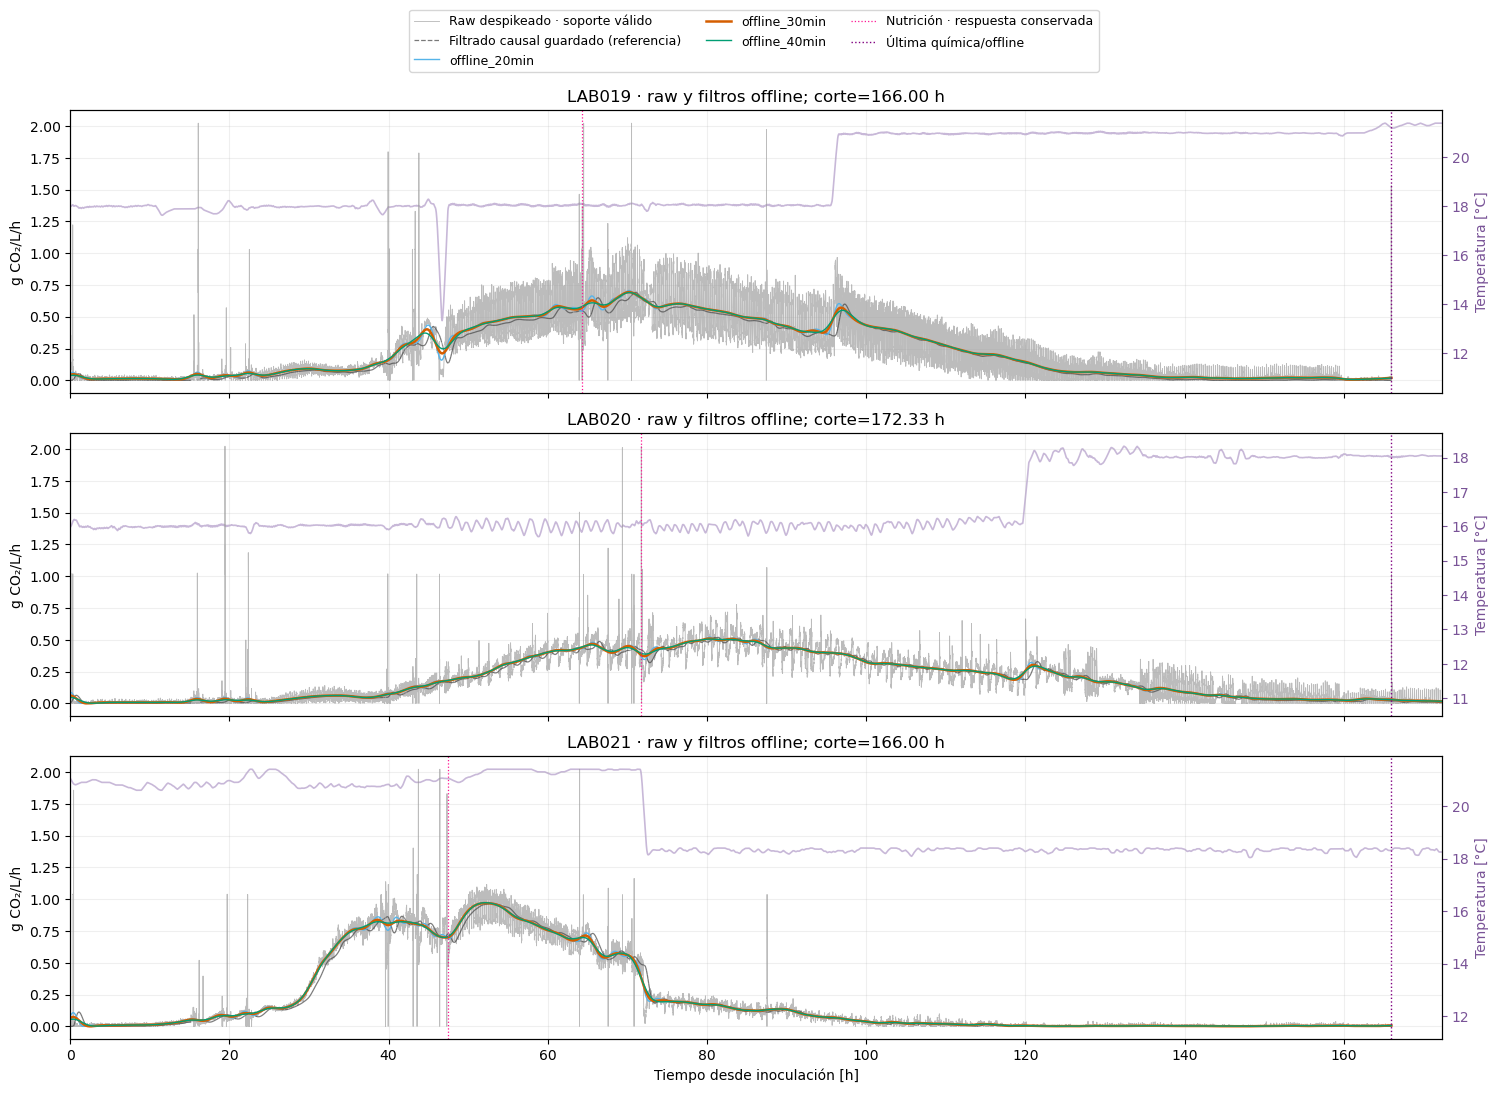

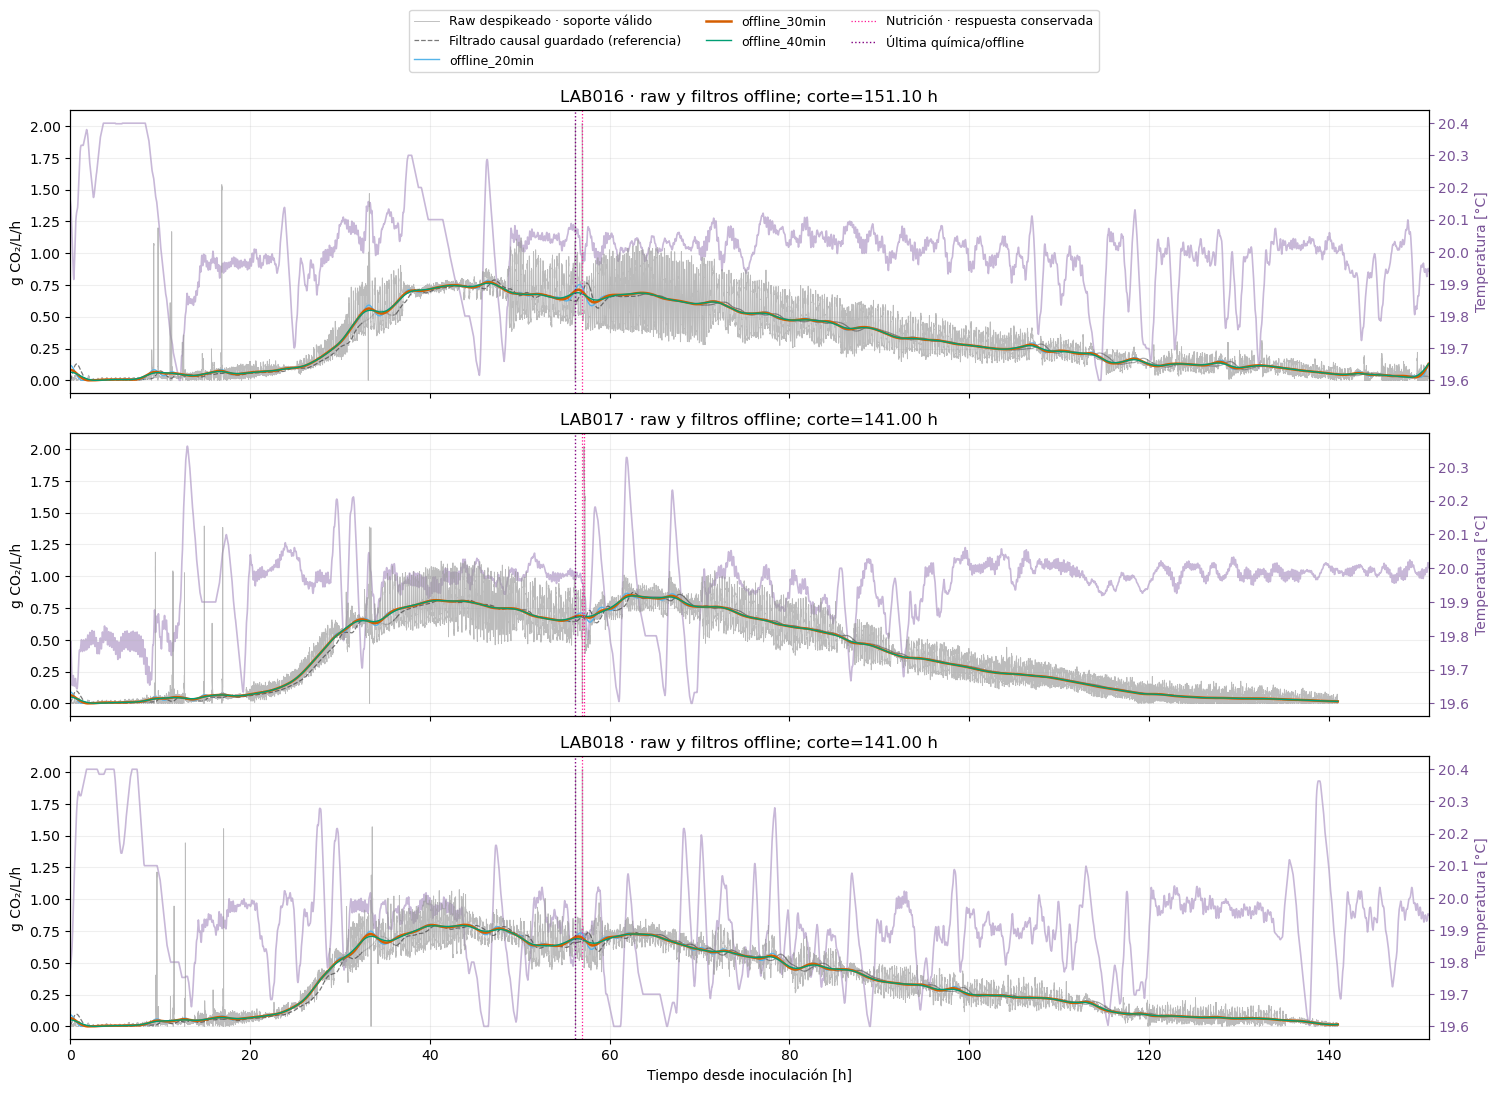

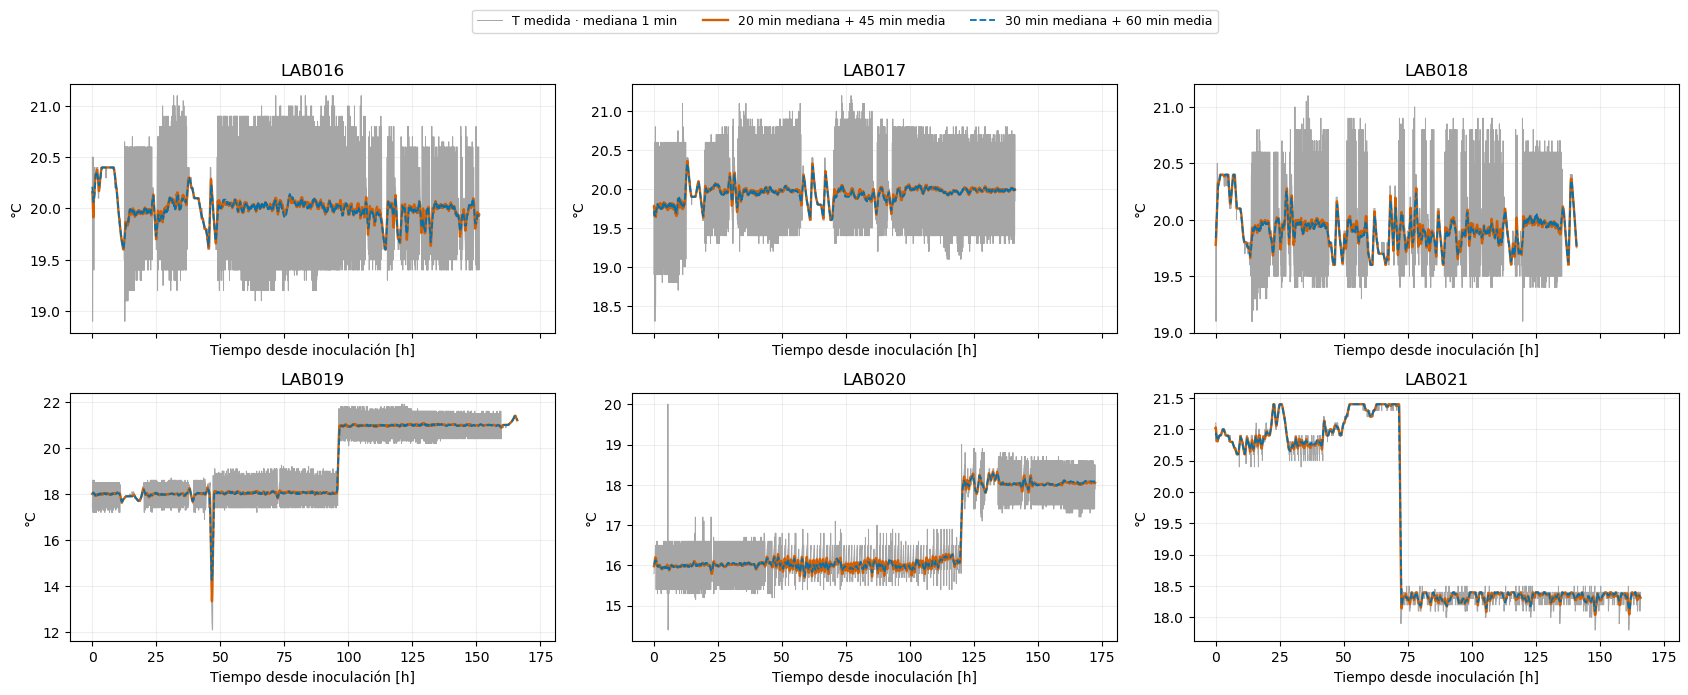

,lab,variant,raw_std_C,filtered_std_C,mean_change_C,max_change_C
0,LAB016,reference_20_45,0.42874,0.14551,-0.02669,1.23111
1,LAB016,strong_30_60,0.42874,0.14467,-0.03061,1.27083
2,LAB017,reference_20_45,0.44968,0.10309,-0.02925,1.37167
3,LAB017,strong_30_60,0.44968,0.09896,-0.03340,1.36208
4,LAB018,reference_20_45,0.35750,0.15616,-0.03623,1.14222
5,LAB018,strong_30_60,0.35750,0.15103,-0.03954,1.13875
6,LAB019,reference_20_45,1.85810,1.80573,-0.01279,2.73889
7,LAB019,strong_30_60,1.85810,1.79842,-0.01638,2.87833
8,LAB020,reference_20_45,1.18717,1.13264,0.00074,4.03667
9,LAB020,strong_30_60,1.18717,1.13377,0.00139,4.07250


In [6]:
CO2_MINUTE=[];TEMP_EXPORT=[];ARTIFACT_ROWS=[]
for cohort in (LABS[3:],LABS[:3]):
    fig,axs=plt.subplots(3,1,figsize=(15,11),sharex=True)
    for ax,lab in zip(axs,cohort):
        d=V.dense[lab];cut=V.horizons[lab]
        t=d.time_h.to_numpy();keep=(t>=0.)&(t<=cut)
        raw=np.where(d.valid_for_fit,d.despiked,np.nan)
        ax.plot(t[keep],raw[keep],c='0.6',lw=.65,alpha=.65,label='Raw despikeado · soporte válido')
        ax.plot(t[keep],d.recorded.to_numpy()[keep],c='0.25',ls='--',lw=.9,alpha=.7,label='Filtrado causal guardado (referencia)')
        for filtering,color in [('offline_20min','#56B4E9'),(PRIMARY,'#D55E00'),('offline_40min','#009E73')]:
            values=np.where(d.valid_for_fit,d[filtering],np.nan)
            ax.plot(t[keep],values[keep],c=color,lw=1.8 if filtering==PRIMARY else 1.,label=filtering)
        temp=V.temperature[lab]
        tx=ax.twinx();tx.set_zorder(ax.get_zorder()-1);ax.patch.set_visible(False)
        tx.plot(temp.time_h,temp.reference_20_45,c='#9273B2',alpha=.5,lw=1.2,label='T filtrada 20/45 min')
        tx.set_ylabel('Temperatura [°C]',color='#795397');tx.tick_params(axis='y',colors='#795397')
        for event_h,dose in V.batches[lab].pulses['N']:
            ax.axvline(event_h,c='deeppink',ls=':',lw=.9,label='Nutrición · respuesta conservada' if event_h==V.batches[lab].pulses['N'][0][0] else None)
        ax.axvline(float(V.coverage.set_index('lab').loc[lab,'last_chemical_or_offline_h']),c='purple',ls=':',lw=1.,label='Última química/offline')
        ax.set(title=f'{lab} · raw y filtros offline; corte={cut:.2f} h',ylabel='g CO₂/L/h',xlim=(0.,max(V.horizons[l] for l in cohort)))
        ax.grid(alpha=.2)
    axs[-1].set_xlabel('Tiempo desde inoculación [h]')
    handles,labels=axs[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',ncol=3,fontsize=9)
    show_v3(fig,legend=True)

fig,axs=plt.subplots(2,3,figsize=(17,7),sharex=True)
for ax,lab in zip(axs.flat,LABS):
    temp=V.temperature[lab];keep=temp.time_h.between(0.,V.horizons[lab])
    ax.plot(temp.time_h[keep],temp.raw_1min[keep],c='0.65',lw=.7,label='T medida · mediana 1 min')
    ax.plot(temp.time_h[keep],temp.reference_20_45[keep],c='#D55E00',lw=1.7,label='20 min mediana + 45 min media')
    ax.plot(temp.time_h[keep],temp.strong_30_60[keep],c='#0072B2',lw=1.3,ls='--',label='30 min mediana + 60 min media')
    ax.set(title=lab,ylabel='°C',xlabel='Tiempo desde inoculación [h]');ax.grid(alpha=.2)
fig.legend(*axs[0,0].get_legend_handles_labels(),loc='upper center',ncol=3,fontsize=9)
show_v3(fig,legend=True)
display(V.temp_audit.round(5))
for lab in LABS:
    d=V.dense[lab].copy()
    CO2_MINUTE.append(d.resample('1min').median(numeric_only=True).assign(lab=lab).reset_index(names='timestamp'))
    TEMP_EXPORT.append(V.temperature[lab].assign(lab=lab).reset_index(names='timestamp'))
    ARTIFACT_ROWS.extend(dict(lab=lab,**event) for event in V.artifacts[lab])
pd.concat(CO2_MINUTE,ignore_index=True).to_csv(OUT/'preprocessed_co2_1min_preview.csv',index=False)
pd.concat(TEMP_EXPORT,ignore_index=True).to_csv(OUT/'temperature_inputs_1min.csv',index=False)
pd.DataFrame(ARTIFACT_ROWS,columns=['lab','start_h','end_h']).to_csv(OUT/'artifact_windows.csv',index=False)
pd.DataFrame(V.nutrition_events).to_csv(OUT/'nutrition_events.csv',index=False)

## 3. Comprobaciones del filtrado: fase, picos y bordes

Una señal gaussiana simétrica permite separar el retardo del filtro de los cambios de forma en una curva real. Se comprueba el máximo, el punto medio de un escalón y que el Hampel retire un outlier aislado sin desplazar los vecinos constantes. El filtro causal se incluye únicamente como control del orden de magnitud del retardo, no para desplazar observaciones.

Se conserva padding impar de seis constantes de tiempo como extensión numérica; no se excluyen los bordes del ajuste. Al suavizar una señal real con varios máximos próximos, el máximo global puede cambiar de uno a otro: las diferencias de hora de la tabla de filtros no son automáticamente un retardo de fase.

In [7]:
FILTER_CHECKS=[]
dt=10.;tt=np.arange(-12*3600.,12*3600.+dt,dt)
gaussian=np.exp(-.5*(tt/(2.*3600.))**2)
step=(tt>=0.).astype(float)
for name,tau in FILTERS.items():
    z=zero_phase(gaussian,tau,dt)
    ss=zero_phase(step,tau,dt)
    peak_shift=float(tt[np.argmax(z)])
    midpoint=float(tt[np.flatnonzero(ss>=.5)[0]])
    assert abs(peak_shift)<=dt and abs(midpoint)<=dt
    FILTER_CHECKS.append(dict(test=name,peak_shift_seconds=peak_shift,step_midpoint_seconds=midpoint,
        amplitude_ratio=float(z.max()/gaussian.max())))
test=np.ones(301);test[150]=50.
despiked,flags=centered_hampel(test,10.)
assert flags.sum()==1 and flags[150] and np.array_equal(despiked,np.ones(301))
causal=signal.sosfilt(butter_sos(1200.,dt),gaussian)
FILTER_CHECKS.append(dict(test='GUI Butterworth causal control',peak_shift_seconds=float(tt[np.argmax(causal)]),
    step_midpoint_seconds=np.nan,amplitude_ratio=float(causal.max())))
FILTER_CHECKS=pd.DataFrame(FILTER_CHECKS)
display(FILTER_CHECKS)
FILTER_CHECKS.to_csv(OUT/'filter_synthetic_checks.csv',index=False)

,test,peak_shift_seconds,step_midpoint_seconds,amplitude_ratio
0,offline_20min,0.0,0.0,0.999683
1,offline_30min,0.0,0.0,0.996745
2,offline_40min,0.0,0.0,0.985943
3,GUI Butterworth causal control,2440.0,NaN,0.999830


## 4. Química con la temperatura filtrada y coherencia del modelo de observación

Se integran las ecuaciones químicas oficiales con saltos de N exactos. La malla de salida de 5 min es más fina que los datos del ajuste. Se repiten las simulaciones con T 20/45, T 30/60 y T con sólo mediana de 1 min para medir cuánto cambia la química al suavizar la temperatura; no se ajusta ningún theta.

La fuente de v2 sigue siendo q_bio=M·max[(1+(b−1)r)q₀+r(qₙ−q₀),0], con puerta por consumo predicho de G+F entre 2 y 10 g/L, b=0.25 y los demás parámetros heredados. El reservorio se integra de forma implícita conservativa. **La predicción que se compara con la observación pasa por el mismo Butterworth offline que los datos**, en la grilla nativa del logger. Esto evita atribuir al reservorio la atenuación de banda del procesamiento. Se guarda por separado la predicción física y la salida del operador de observación.

Hampel se utiliza para despikear mediciones. El modelo determinista no contiene el ruido ni los artefactos de bomba; se comprueba al final que aplicarle Hampel también no cambia materialmente su salida filtrada. El balance de masa se verifica sobre el reservorio físico, no sobre una señal suavizada de observación.

In [8]:
CHEM_CONTEXT=[]
for context in ('reference_20_45','strong_30_60','raw_1min'):
    V.configure_temperature(context);V.prepare_all()
    for case in ('theta_full','theta_defaults'):CHEM_CONTEXT.append(V.chemistry_v3(case))
    print('Química integrada:',context,flush=True)
CHEM_METRICS=pd.concat(CHEM_CONTEXT,ignore_index=True)
display(CHEM_METRICS.groupby(['temperature','theta','channel']).RMSE.mean().unstack('channel').round(4))
V.set_context('reference_20_45')
display(V.initials)
display(V.biomass[['lab','sample','t_h','X_viable_g_l']].round(5))
CHEM_METRICS.to_csv(OUT/'chemistry_metrics.csv',index=False)

Química integrada: reference_20_45


Química integrada: strong_30_60


Química integrada: raw_1min


channel                               E        F        G       GF        N
temperature     theta                                                      
raw_1min        theta_defaults  14.1457  15.7752  14.6306  27.6716  28.0775
                theta_full       7.6559   9.8719  13.3557  19.3117  28.0386
reference_20_45 theta_defaults  14.1529  15.7797  14.6340  27.6801  28.0930
                theta_full       7.6584   9.8848  13.3632  19.3327  28.0654
strong_30_60    theta_defaults  14.1541  15.7809  14.6354  27.6819  28.0914
                theta_full       7.6579   9.8871  13.3652  19.3355  28.0562

,source,X,Xd,N,G,F,E,Gly,N_events,horizon_h
lab,,,,,,,,,,
LAB016,X0 por 13 millones de células viables/mL del u...,0.390000,0.000000,0.214330,84.158815,88.341185,0.000000,1.14,"((56.93555555555583, 0.14),)",151.100278
LAB017,X0 por 13 millones de células viables/mL del u...,0.390000,0.000000,0.214330,84.158815,88.341185,0.000000,1.14,"((56.933611111110835, 0.14), (57.1338888888888...",151.098889
LAB018,X0 por 13 millones de células viables/mL del u...,0.390000,0.000000,0.214330,84.158815,88.341185,0.000000,1.14,"((56.93166666666694, 0.14),)",151.096944
LAB019,N inicial m1 del CSV corregido; biomasa viable...,0.283162,0.032661,0.230025,79.190000,78.970000,12.075372,1.22,"((64.33333333333277, 0.08),)",166.000000
LAB020,N inicial m1 del CSV corregido; biomasa viable...,0.153342,0.032661,0.225556,77.940000,79.520000,11.917524,1.38,"((71.66666666666694, 0.08),)",166.000000
LAB021,N inicial m1 del CSV corregido; biomasa viable...,0.136153,0.032661,0.231202,80.190000,81.040000,11.759676,1.28,"((47.5, 0.08),)",166.000000


,lab,sample,t_h,X_viable_g_l
0,LAB016,LAB016-1,9.93472,0.43215
1,LAB016,LAB016-2,11.43472,0.27192
2,LAB016,LAB016-8,56.18472,1.39875
3,LAB017,LAB017-1,9.93333,0.24067
4,LAB017,LAB017-2,11.43333,0.17170
5,LAB017,LAB017-8,56.18333,1.12215
6,LAB018,LAB018-1,10.56306,0.25796
7,LAB018,LAB018-2,10.93139,0.23153
8,LAB018,LAB018-8,56.18139,1.73975


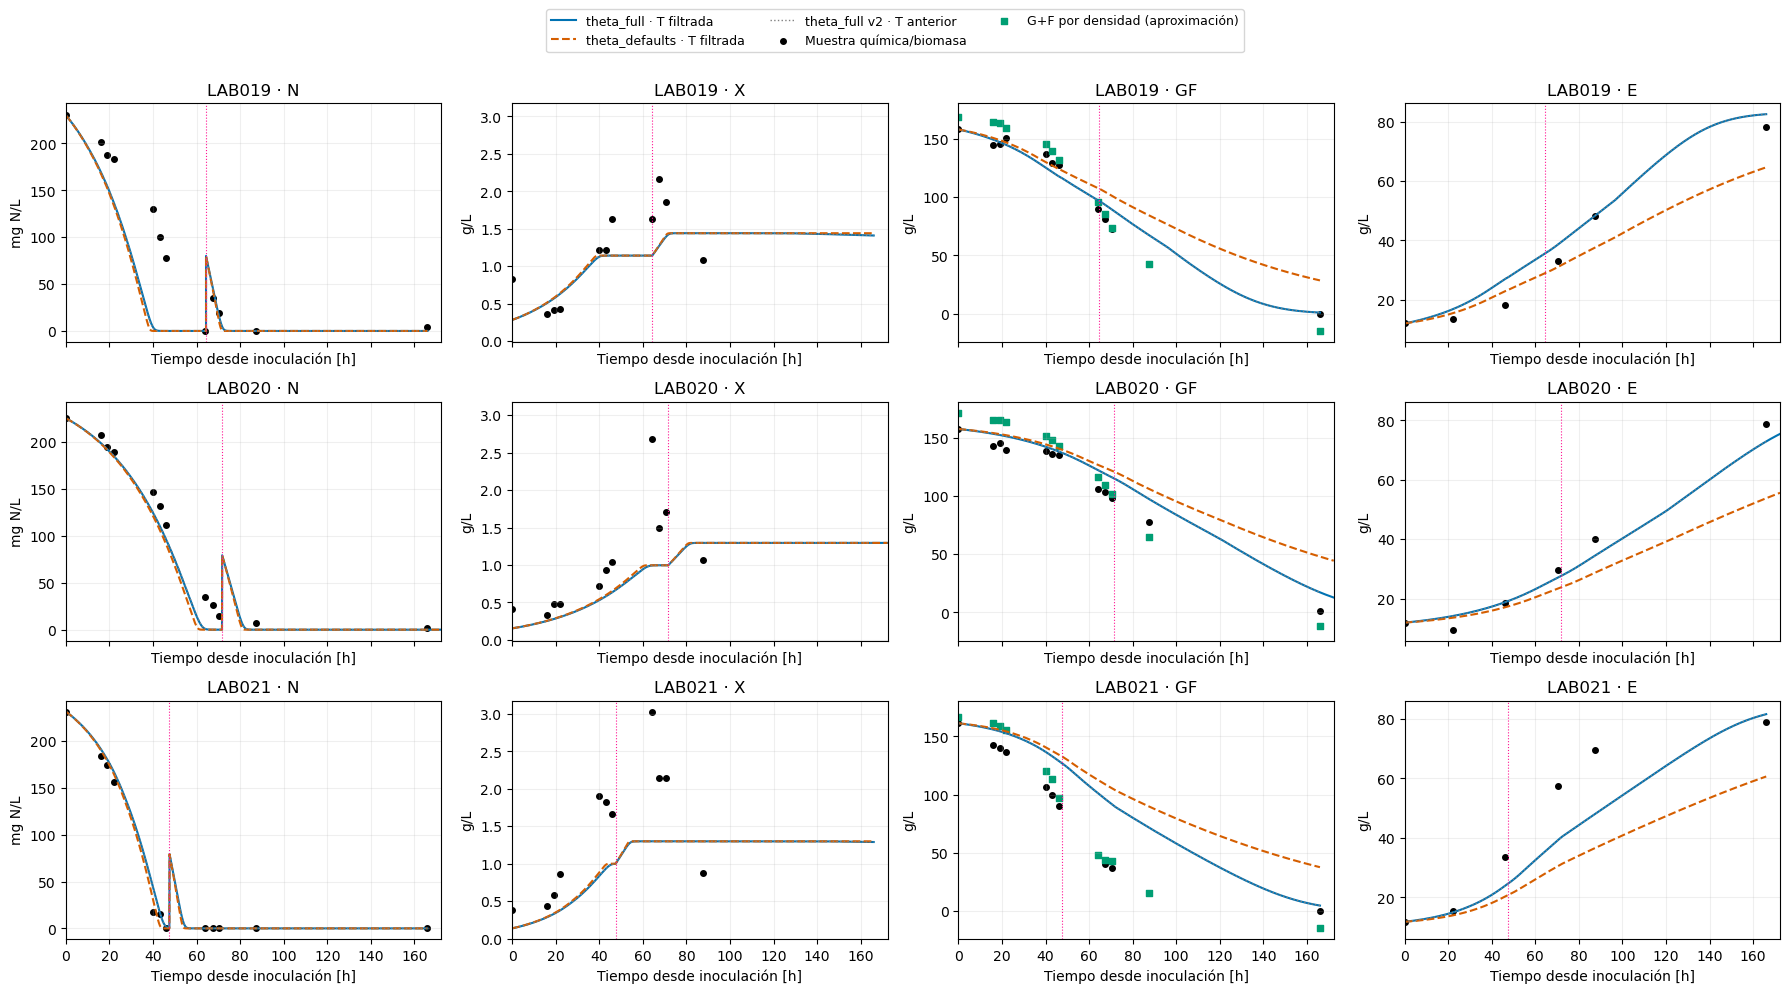

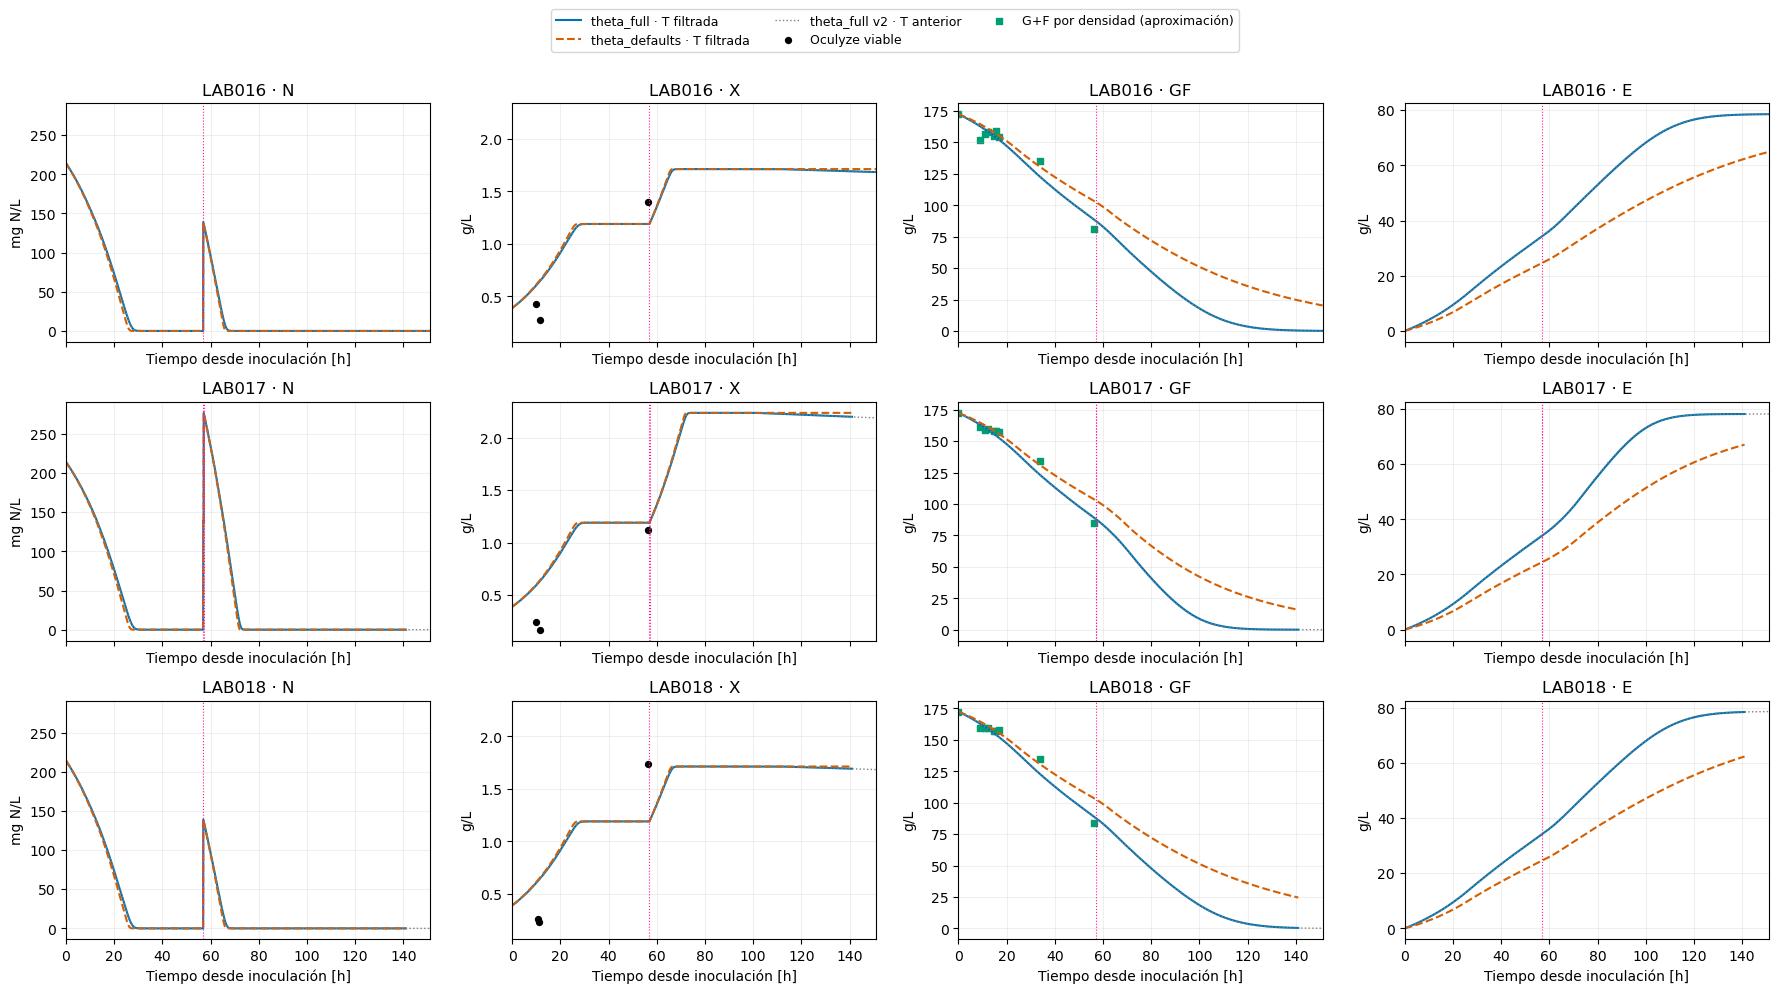

In [9]:
for cohort in (LABS[3:],LABS[:3]):
    fig,axs=plt.subplots(3,4,figsize=(18,10),sharex=True,sharey='col')
    for i,lab in enumerate(cohort):
        for j,(channel,column,mult,unit) in enumerate([('N','YAN_mg_l',1000.,'mg N/L'),
            ('X','X_viable_g_l',1.,'g/L'),('GF','GF_g_l',1.,'g/L'),('E','E_g_l',1.,'g/L')]):
            ax=axs[i,j]
            for case,color,style in [('theta_full','#0072B2','-'),('theta_defaults','#D55E00','--')]:
                cr=V.cores[case,lab];keep=cr.index<=V.horizons[lab]
                ax.plot(cr.index[keep],cr[channel][keep]*mult,c=color,ls=style,label=case+' · T filtrada')
            previous=V.previous_chemistry.query('theta == "theta_full" and lab == @lab')
            ax.plot(previous.t_h,previous[channel]*mult,c='0.5',ls=':',lw=1.,label='theta_full v2 · T anterior')
            if lab in LABS[3:]:
                pts=V.chem[V.chem.lab.eq(lab)&~V.chem.is_NUT][['t_h',column]].dropna()
                ax.scatter(pts.t_h,pts[column],c='black',s=16,label='Muestra química/biomasa')
            elif channel=='X':
                pts=V.biomass[V.biomass.lab.eq(lab)]
                ax.scatter(pts.t_h,pts.X_viable_g_l,c='black',s=18,label='Oculyze viable')
            if channel=='GF':
                pts=V.density[V.density.lab.eq(lab)]
                ax.scatter(pts.t_h,pts.GF_density_g_l,c='#009E73',marker='s',s=18,label='G+F por densidad (aproximación)')
            for t,dose in V.batches[lab].pulses['N']:ax.axvline(t,c='deeppink',ls=':',lw=.8)
            ax.set(title=f'{lab} · {channel}',ylabel=unit,xlabel='Tiempo desde inoculación [h]',xlim=(0.,max(V.horizons[l] for l in cohort)))
            ax.grid(alpha=.2)
    handles={}
    for ax in axs[0]:
        hh,ll=ax.get_legend_handles_labels()
        for h,l in zip(hh,ll):handles.setdefault(l,h)
    fig.legend(list(handles.values()),list(handles),loc='upper center',ncol=3,fontsize=9)
    show_v3(fig,legend=True)

## 5. Ajuste principal Z1/Z2 y separación de calibración y transferencia

Z1 estima sólo `matrix_gain`, con k y saturación heredados. Z2 estima k, saturación y ganancia dentro de los mismos límites de v2, con tres inicializaciones. Se conservan el rendimiento CO₂/E y la conversión SCCM→g/L/h. La fuente no utiliza CO₂ observado para activar la fermentación.

Cada LAB pesa igual mediante residuos divididos por √n. Para y≥0.05 g/L/h se usa ŷ−y; por debajo del límite se penaliza max(ŷ−0.05,0). **Todos los RMSE publicados son sin censura.** Los puntos filtrados están correlacionados; la razón singular del Jacobiano es un diagnóstico local, no un intervalo de confianza ni evidencia de muestras independientes.

Se presentan: ajuste conjunto de seis LAB (descriptivo), entrenamiento en LAB019–021 y predicción de LAB016–018 (transferencia principal), y entrenamiento inverso (comprobación adicional). No se selecciona la intensidad del filtro usando el holdout. Los parámetros v2 se reevalúan bajo las mismas entradas, operador y observaciones v3 para una comparación justa; sus antiguos RMSE horarios no se comparan directamente con los nuevos RMSE de diez minutos.

In [10]:
GROUPS={'all_six':LABS,'train_019_021':LABS[3:],'train_016_018':LABS[:3]}
for case in ('theta_full','theta_defaults'):
    for label,training in GROUPS.items():V.fit_layer(case,training,label)
    pd.DataFrame(V.fit_table).to_csv(OUT/'fit_parameters.csv',index=False)
FIT_TABLE=pd.DataFrame(V.fit_table)
display(FIT_TABLE.round(6))
MAIN_METRICS=[];MAIN_CURVES=[];PARAMETER_CONTROL=[]
for case in ('theta_full','theta_defaults'):
    for training in GROUPS:
        for stage in ('Z1','Z2'):
            key=('reference_20_45',PRIMARY,'v2',case,training,stage)
            params=V.v3_fits[key]
            met=V.metrics_v3(case,params,LABS).assign(training=training,stage=stage,source='v3_fit')
            MAIN_METRICS.append(met)
            for lab in LABS:
                cr=V.curve_v3(case,lab,params)
                MAIN_CURVES.append(cr[cr.t_h<=V.horizons[lab]+1e-8].assign(lab=lab,theta=case,training=training,stage=stage))
        old=V.previous_parameters.query('theta == @case and training == @training and stage == "Z2"').iloc[0]
        params={**V.old,**{p:float(old[p]) for p in ('kCO2_release_h','CO2sat_scale','matrix_gain')}}
        control=V.metrics_v3(case,params,LABS).assign(training=training,stage='Z2',source='v2_parameters_on_v3_data')
        PARAMETER_CONTROL.append(control)
METRICS=pd.concat(MAIN_METRICS+PARAMETER_CONTROL,ignore_index=True)
CURVES=pd.concat(MAIN_CURVES,ignore_index=True)
METRICS['role']=['calibration' if row.training=='all_six' or row.lab in GROUPS[row.training] else 'transfer' for row in METRICS.itertuples()]
display(METRICS.query('window == "all"').groupby(['theta','training','stage','source','role']).RMSE.mean().to_frame().round(5))
METRICS.to_csv(OUT/'metrics.csv',index=False)
CURVES.to_csv(OUT/'gas_trajectories.csv',index=False)

reference_20_45 offline_30min v2 theta_full all_six Z1/Z2 0.12011 0.106602


reference_20_45 offline_30min v2 theta_full train_019_021 Z1/Z2 0.055775 0.053997


reference_20_45 offline_30min v2 theta_full train_016_018 Z1/Z2 0.059046 0.034594


reference_20_45 offline_30min v2 theta_defaults all_six Z1/Z2 0.129546 0.11833


reference_20_45 offline_30min v2 theta_defaults train_019_021 Z1/Z2 0.058614 0.057874


reference_20_45 offline_30min v2 theta_defaults train_016_018 Z1/Z2 0.064204 0.044198


,temperature,filtering,mode,theta,training,labs,stage,success,objective,jacobian_ratio,active_bounds,kCO2_release_h,CO2sat_scale,matrix_gain
0,reference_20_45,offline_30min,v2,theta_full,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z1,True,0.120110,NaN,,0.424588,0.351390,0.924954
1,reference_20_45,offline_30min,v2,theta_full,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z2,True,0.106602,0.001047,,0.192035,1.723302,0.953285
2,reference_20_45,offline_30min,v2,theta_full,train_019_021,"LAB019,LAB020,LAB021",Z1,True,0.055775,NaN,,0.424588,0.351390,1.055119
3,reference_20_45,offline_30min,v2,theta_full,train_019_021,"LAB019,LAB020,LAB021",Z2,True,0.053997,0.000215,,2.000835,0.999955,1.054708
4,reference_20_45,offline_30min,v2,theta_full,train_016_018,"LAB016,LAB017,LAB018",Z1,True,0.059046,NaN,,0.424588,0.351390,0.880749
5,reference_20_45,offline_30min,v2,theta_full,train_016_018,"LAB016,LAB017,LAB018",Z2,True,0.034594,0.014447,CO2sat_scale,0.148732,2.500000,0.935727
6,reference_20_45,offline_30min,v2,theta_defaults,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z1,True,0.129546,NaN,,0.424588,0.351390,1.293795
7,reference_20_45,offline_30min,v2,theta_defaults,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z2,True,0.118330,0.002369,,0.214901,1.060619,1.322104
8,reference_20_45,offline_30min,v2,theta_defaults,train_019_021,"LAB019,LAB020,LAB021",Z1,True,0.058614,NaN,,0.424588,0.351390,1.505566
9,reference_20_45,offline_30min,v2,theta_defaults,train_019_021,"LAB019,LAB020,LAB021",Z2,True,0.057874,0.000185,,2.480408,1.471286,1.501647


RMSE
theta          training      stage source                   role                
theta_defaults all_six       Z1    v3_fit                   calibration  0.14549
                             Z2    v2_parameters_on_v3_data calibration  0.13562
                                   v3_fit                   calibration  0.13698
               train_016_018 Z1    v3_fit                   calibration  0.14681
                                                            transfer     0.14597
                             Z2    v2_parameters_on_v3_data calibration  0.12192
                                                            transfer     0.15398
                                   v3_fit                   calibration  0.12160
                                                            transfer     0.15156
               train_019_021 Z1    v3_fit                   calibration  0.13929
                                                            transfer     0.17543
                             Z2    v2_parameters_on_v3_data calibration  0.13894
                                                            transfer     0.17809
                                   v3_fit                   calibration  0.13968
                                                            transfer     0.18809
theta_full     all_six       Z1    v3_fit                   calibration  0.13986
                             Z2    v2_parameters_on_v3_data calibration  0.12768
                                   v3_fit                   calibration  0.12839
               train_016_018 Z1    v3_fit                   calibration  0.14075
                                                            transfer     0.14052
                             Z2    v2_parameters_on_v3_data calibration  0.10794
                                                            transfer     0.15257
                                   v3_fit                   calibration  0.10742
                                                            transfer     0.14997
               train_019_021 Z1    v3_fit                   calibration  0.13521
                                                            transfer     0.16344
                             Z2    v2_parameters_on_v3_data calibration  0.13375
                                                            transfer     0.17766
                                   v3_fit                   calibration  0.13421
                                                            transfer     0.17826

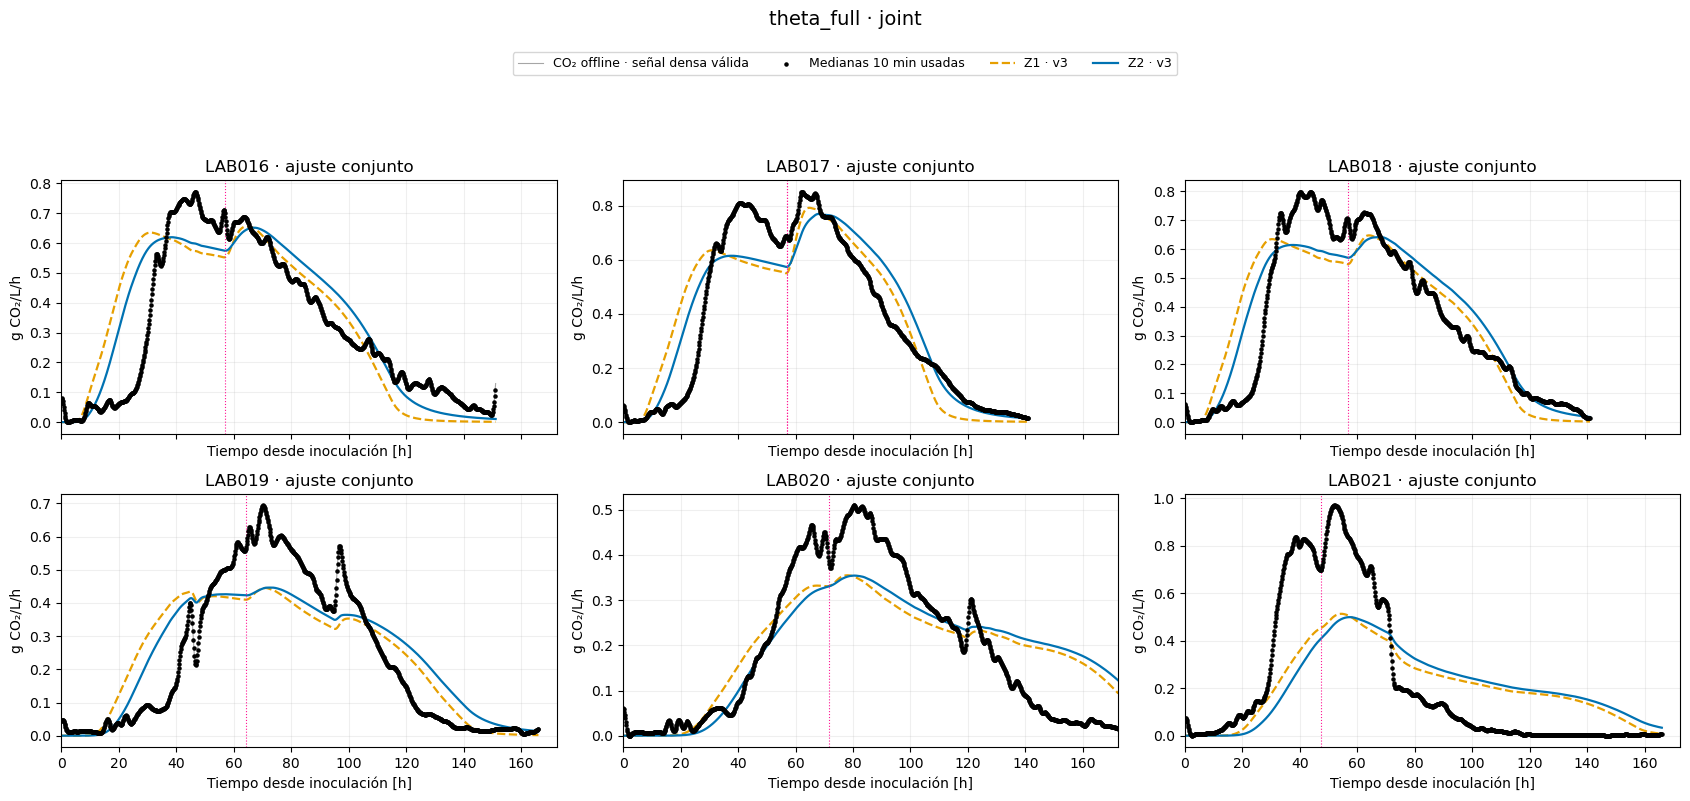

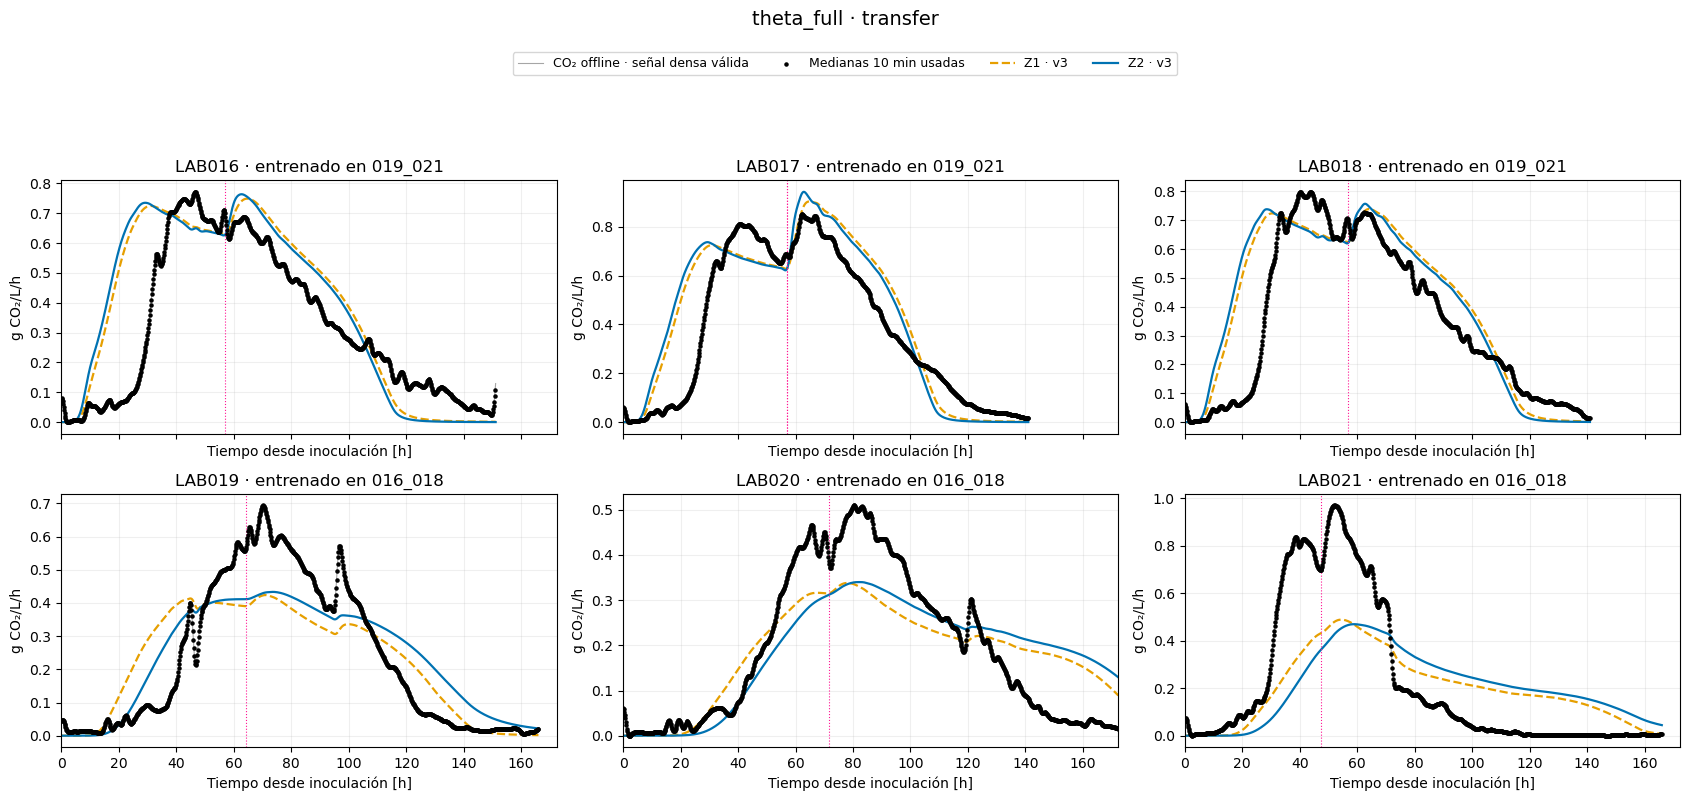

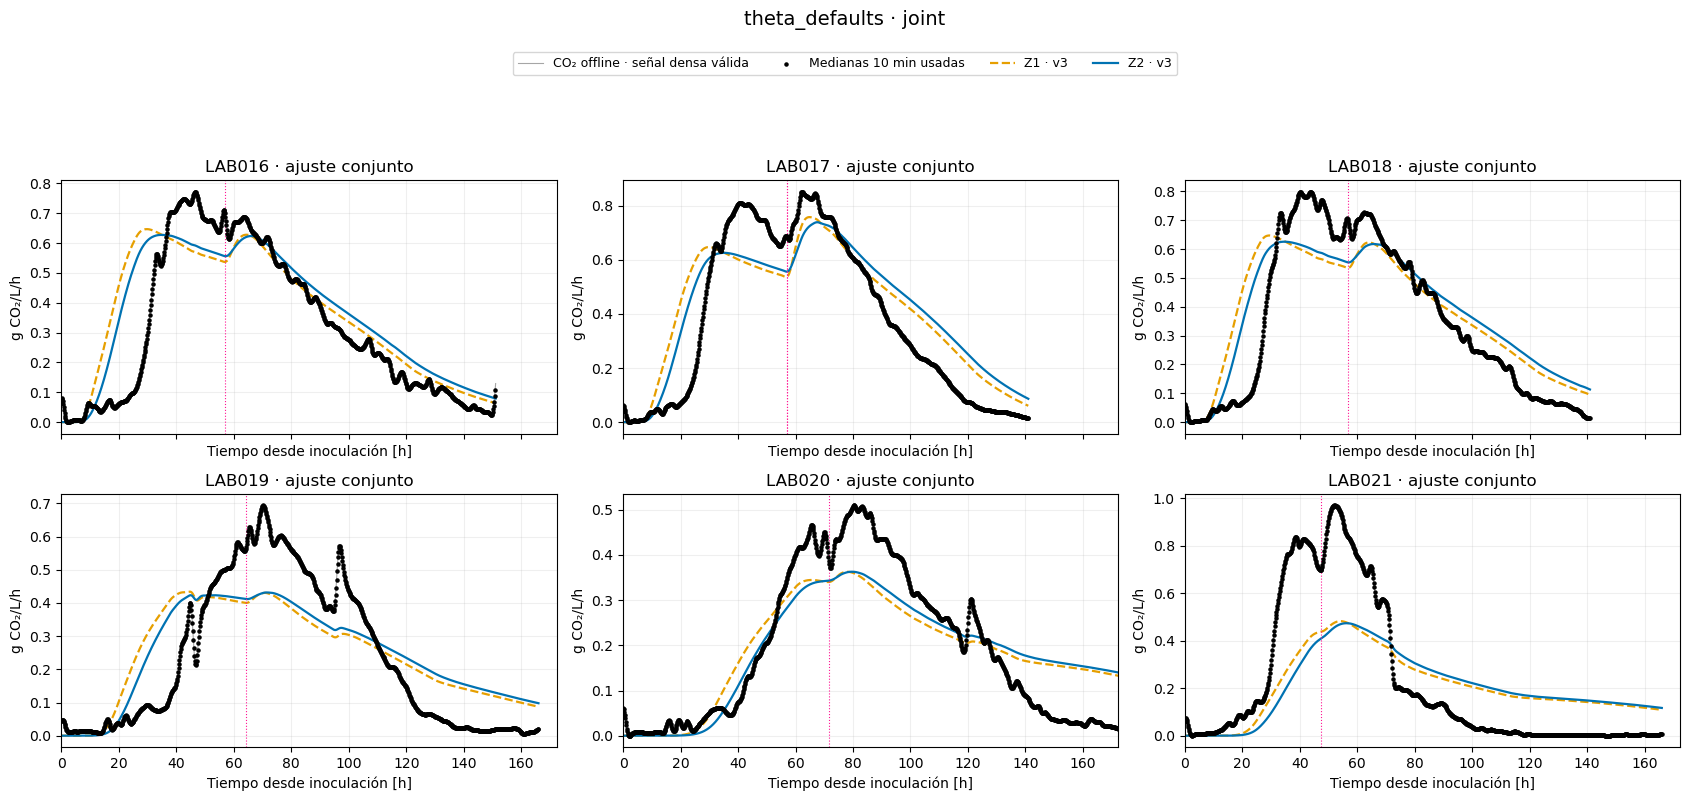

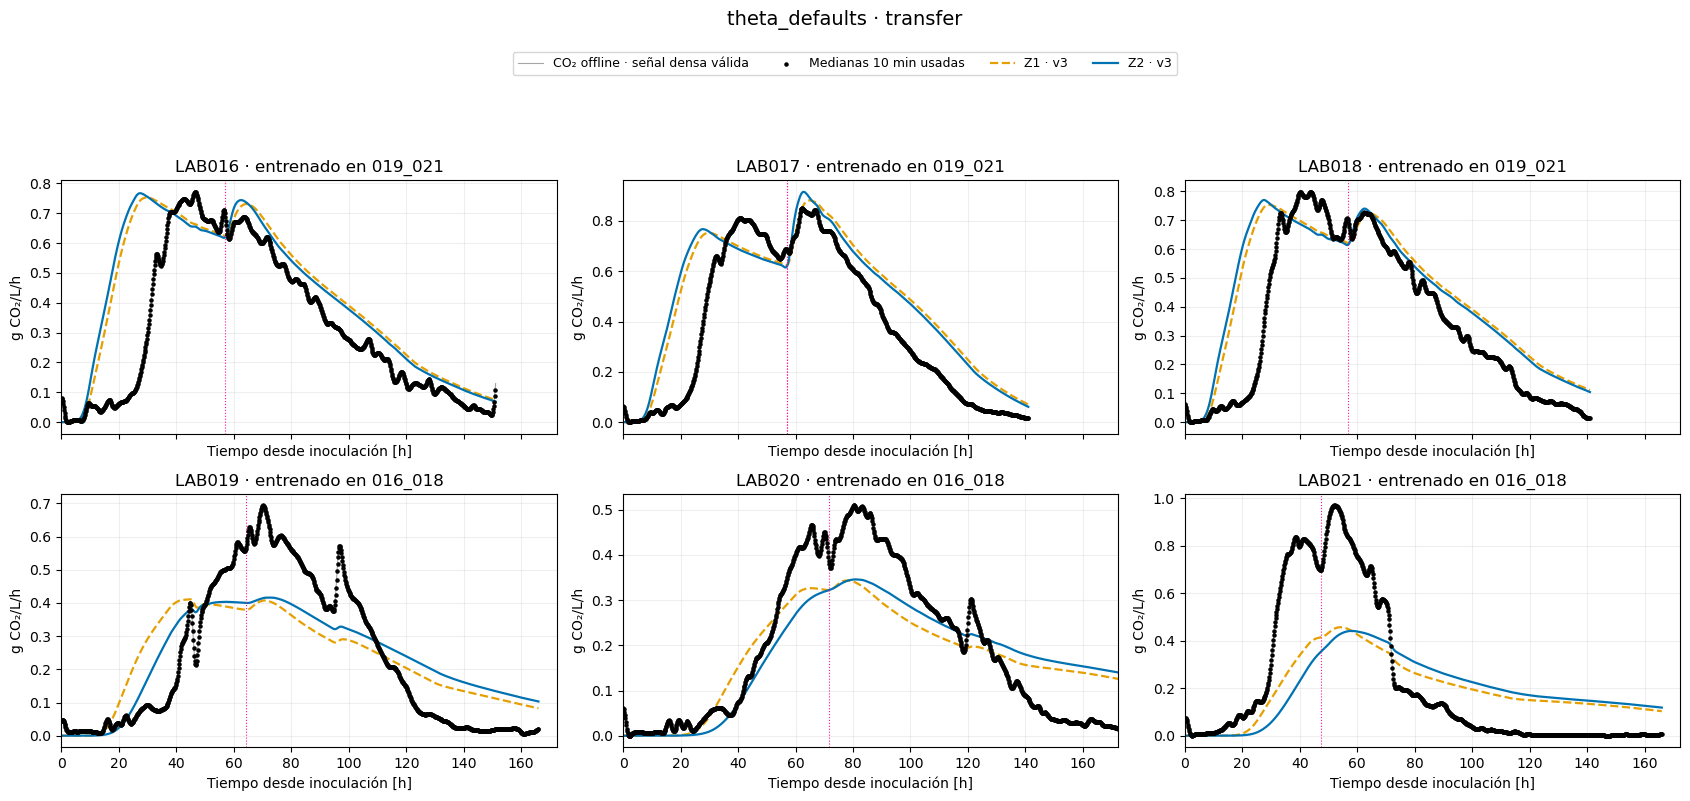

In [11]:
for case in ('theta_full','theta_defaults'):
    for kind in ('joint','transfer'):
        fig,axs=plt.subplots(2,3,figsize=(17,8),sharex='col')
        for ax,lab in zip(axs.flat,LABS):
            training='all_six' if kind=='joint' else 'train_019_021' if lab in LABS[:3] else 'train_016_018'
            dense=V.dense[lab];keep=dense.time_h.between(0.,V.horizons[lab])
            ax.plot(dense.time_h[keep],np.where(dense.valid_for_fit,dense[PRIMARY],np.nan)[keep],c='0.65',lw=.8,label='CO₂ offline · señal densa válida')
            obs=V.observations[PRIMARY,lab]
            ax.scatter(obs.t_h,obs.y,c='black',s=5,label='Medianas 10 min usadas',zorder=5)
            for stage,color,style in [('Z1','#E69F00','--'),('Z2','#0072B2','-')]:
                curve=CURVES.query('theta == @case and lab == @lab and training == @training and stage == @stage')
                ax.plot(curve.t_h,curve.CO2_observed_operator,c=color,ls=style,lw=1.6,label=stage+' · v3')
            for t,dose in V.batches[lab].pulses['N']:ax.axvline(t,c='deeppink',ls=':',lw=.8)
            ax.set(title=f'{lab} · '+('ajuste conjunto' if kind=='joint' else f'entrenado en {training[6:]}'),
                   xlabel='Tiempo desde inoculación [h]',ylabel='g CO₂/L/h',xlim=(0.,max(V.horizons.values())))
            ax.grid(alpha=.2)
        fig.legend(*axs[0,0].get_legend_handles_labels(),loc='upper center',ncol=4,fontsize=9)
        fig.suptitle(case+' · '+kind,y=1.015,fontsize=14)
        show_v3(fig,legend=True)

## 6. Sensibilidad al filtrado de CO₂ y temperatura

Se repite el entrenamiento LAB019–021 con τ=20 y 40 min manteniendo la química principal. Se repite después con T 30/60 y τ=30. Se publican errores sobre cada señal procesada y, por separado, sobre la misma mediana de diez minutos del raw despikeado, comparada con la predicción física sin Butterworth. Así un filtro más fuerte no gana automáticamente por haber borrado variación real de su objetivo.

El caso principal sigue siendo 30 min y T 20/45, fijado antes de estimar parámetros. Las diferencias de transferencia de esta tabla son exploratorias. El suavizado no demuestra por sí solo que una oscilación atenuada sea ruido: puede contener respuesta al control térmico. Tampoco reestima la dependencia Arrhenius de la cinética.

In [12]:
SENSITIVITY=[]
for context,filtering in [('reference_20_45','offline_20min'),('reference_20_45',PRIMARY),
                           ('reference_20_45','offline_40min'),('strong_30_60',PRIMARY)]:
    V.set_context(context)
    for case in ('theta_full','theta_defaults'):
        key=(context,filtering,'v2',case,'train_019_021','Z2')
        if key not in V.v3_fits:V.fit_layer(case,LABS[3:],'train_019_021',filtering=filtering,starts=2)
        params=V.v3_fits[key]
        for common in (False,True):
            met=V.metrics_v3(case,params,LABS,filtering=filtering,common_target=common)
            SENSITIVITY.append(met.assign(temperature=context,filtering=filtering))
SENSITIVITY=pd.concat(SENSITIVITY,ignore_index=True)
SENSITIVITY['cohort']=np.where(SENSITIVITY.lab.isin(LABS[:3]),'transfer_016_018','train_019_021')
display(SENSITIVITY.query('window == "all"').groupby(['temperature','filtering','theta','target','cohort']).RMSE.mean().to_frame().round(5))
SENSITIVITY.to_csv(OUT/'filter_sensitivity.csv',index=False)
V.set_context('reference_20_45')

reference_20_45 offline_20min v2 theta_full train_019_021 Z1/Z2 0.05611 0.054311


reference_20_45 offline_20min v2 theta_defaults train_019_021 Z1/Z2 0.058952 0.058193


reference_20_45 offline_40min v2 theta_full train_019_021 Z1/Z2 0.055556 0.053801


reference_20_45 offline_40min v2 theta_defaults train_019_021 Z1/Z2 0.058396 0.057676


strong_30_60 offline_30min v2 theta_full train_019_021 Z1/Z2 0.055803 0.054017


strong_30_60 offline_30min v2 theta_defaults train_019_021 Z1/Z2 0.058639 0.057897


RMSE
temperature     filtering     theta          target                cohort                   
reference_20_45 offline_20min theta_defaults despiked_raw_common   train_019_021     0.15138
                                                                   transfer_016_018  0.19820
                                             same_offline_operator train_019_021     0.14009
                                                                   transfer_016_018  0.18825
                              theta_full     despiked_raw_common   train_019_021     0.14563
                                                                   transfer_016_018  0.18767
                                             same_offline_operator train_019_021     0.13465
                                                                   transfer_016_018  0.17860
                offline_30min theta_defaults despiked_raw_common   train_019_021     0.15138
                                                                   transfer_016_018  0.19829
                                             same_offline_operator train_019_021     0.13968
                                                                   transfer_016_018  0.18809
                              theta_full     despiked_raw_common   train_019_021     0.14562
                                                                   transfer_016_018  0.18759
                                             same_offline_operator train_019_021     0.13421
                                                                   transfer_016_018  0.17826
                offline_40min theta_defaults despiked_raw_common   train_019_021     0.15135
                                                                   transfer_016_018  0.19772
                                             same_offline_operator train_019_021     0.13938
                                                                   transfer_016_018  0.18733
                              theta_full     despiked_raw_common   train_019_021     0.14562
                                                                   transfer_016_018  0.18754
                                             same_offline_operator train_019_021     0.13395
                                                                   transfer_016_018  0.17805
strong_30_60    offline_30min theta_defaults despiked_raw_common   train_019_021     0.15144
                                                                   transfer_016_018  0.19838
                                             same_offline_operator train_019_021     0.13974
                                                                   transfer_016_018  0.18817
                              theta_full     despiked_raw_common   train_019_021     0.14562
                                                                   transfer_016_018  0.18739
                                             same_offline_operator train_019_021     0.13423
                                                                   transfer_016_018  0.17806

## 7. Comparación adicional: mezcla positiva y ganancia 1.025

Se conserva el interés del seguimiento anterior: comparar la fuente original con una mezcla M·[(1−r)q₀+b·r·qₙ] que evita la resta final de la trayectoria sin nutrición. Es una modificación estructural local, **no forma parte de la recalibración principal Z1/Z2 de v3**. Se prueban `theta_full` y el mismo theta con sN=18; cada uno se ajusta sólo con LAB019–021. Además se muestra el cambio exclusivo a matrix_gain=1.025 sin reajuste. El operador offline y las entradas son los mismos en todos los casos.

reference_20_45 offline_30min positive_mix theta_full train_019_021 Z1/Z2 0.044921 0.038171


reference_20_45 offline_30min positive_mix theta_full_sN18 train_019_021 Z1/Z2 0.044636 0.037895


RMSE
case            scenario                cohort                   
theta_full      positive_mix            train_019_021     0.10611
                                        transfer_016_018  0.18205
                positive_mix_gain_1p025 train_019_021     0.12187
                                        transfer_016_018  0.12757
theta_full_sN18 positive_mix            train_019_021     0.10588
                                        transfer_016_018  0.18063
                positive_mix_gain_1p025 train_019_021     0.12120
                                        transfer_016_018  0.12767

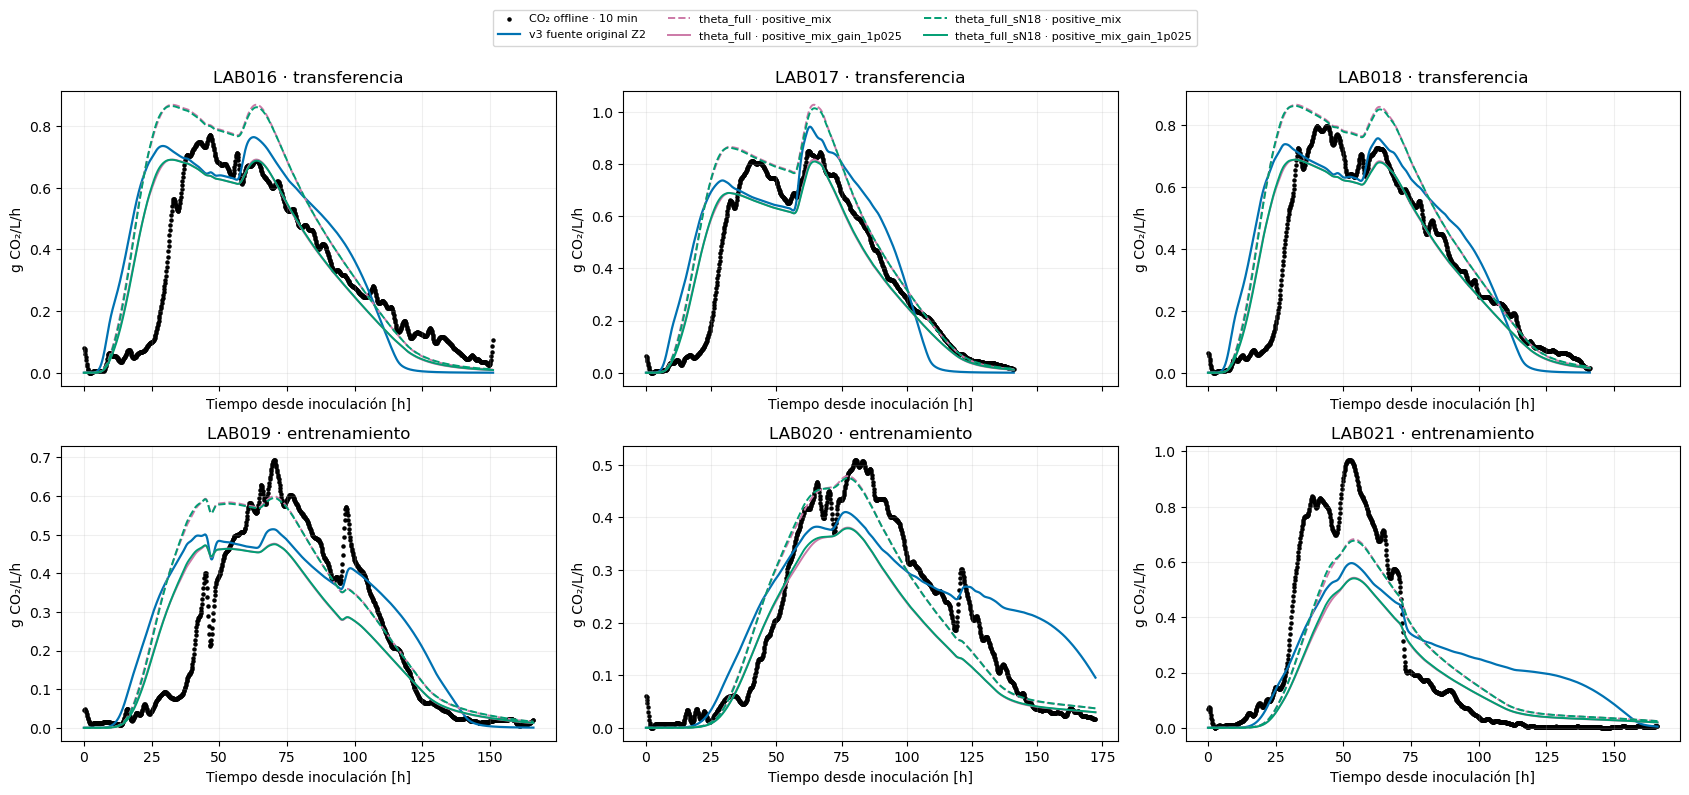

In [13]:
EXTRA_FITS={};EXTRA_METRICS=[];EXTRA_CURVES=[]
case='theta_full_sN18'
V.prepare(case,{**V.thetas['theta_full'],'sN':18.},LABS)
for case in ('theta_full','theta_full_sN18'):
    z1,z2=V.fit_layer(case,LABS[3:],'train_019_021',mode='positive_mix',starts=3)
    for label,params in [('positive_mix',z2),('positive_mix_gain_1p025',{**z2,'matrix_gain':1.025})]:
        EXTRA_FITS[case,label]=params
        EXTRA_METRICS.append(V.metrics_v3(case,params,LABS,mode='positive_mix').assign(case=case,scenario=label))
        for lab in LABS:
            curve=V.curve_v3(case,lab,params,mode='positive_mix')
            EXTRA_CURVES.append(curve[curve.t_h<=V.horizons[lab]].assign(lab=lab,case=case,scenario=label))
EXTRA_METRICS=pd.concat(EXTRA_METRICS,ignore_index=True)
EXTRA_CURVES=pd.concat(EXTRA_CURVES,ignore_index=True)
display(EXTRA_METRICS.query('window == "all"').assign(cohort=lambda d:np.where(d.lab.isin(LABS[:3]),'transfer_016_018','train_019_021')).groupby(['case','scenario','cohort']).RMSE.mean().to_frame().round(5))
fig,axs=plt.subplots(2,3,figsize=(17,8),sharex='col')
for ax,lab in zip(axs.flat,LABS):
    obs=V.observations[PRIMARY,lab];ax.scatter(obs.t_h,obs.y,c='black',s=5,label='CO₂ offline · 10 min')
    base=CURVES.query('theta == "theta_full" and training == "train_019_021" and stage == "Z2" and lab == @lab')
    ax.plot(base.t_h,base.CO2_observed_operator,c='#0072B2',lw=1.6,label='v3 fuente original Z2')
    for case,color in [('theta_full','#CC79A7'),('theta_full_sN18','#009E73')]:
        for scenario,style in [('positive_mix','--'),('positive_mix_gain_1p025','-')]:
            curve=EXTRA_CURVES.query('case == @case and scenario == @scenario and lab == @lab')
            ax.plot(curve.t_h,curve.CO2_observed_operator,c=color,ls=style,lw=1.4,label=case+' · '+scenario)
    ax.set(title=lab+' · '+('transferencia' if lab in LABS[:3] else 'entrenamiento'),xlabel='Tiempo desde inoculación [h]',ylabel='g CO₂/L/h');ax.grid(alpha=.2)
fig.legend(*axs[0,0].get_legend_handles_labels(),loc='upper center',ncol=3,fontsize=8)
show_v3(fig,legend=True)
EXTRA_METRICS.to_csv(OUT/'positive_mix_metrics.csv',index=False)
EXTRA_CURVES.to_csv(OUT/'positive_mix_curves.csv',index=False)

## 8. Verificación numérica y alcance

Se comprueban balances físicos, positividad, inventario N con pulsos exactos, convergencia del reservorio y efecto del operador de observación. El Hampel se aplica a las predicciones finales como auditoría: se compara con el operador Butterworth usado durante la optimización para verificar si la ausencia de outliers del modelo hace válida esa simplificación. Se exporta su diferencia, sin confundirla con error químico.

No se interpretan las nuevas ganancias como rendimientos químicos. La cancelación de fuentes de v2, las condiciones iniciales inciertas, las muestras de NUT sin hora confirmada y los errores de química de LAB021 siguen siendo limitaciones posibles. El filtrado centrado de temperatura modifica la entrada de un modelo no lineal; la cinética evaluada a T suavizada no equivale exactamente al promedio de la cinética a T instantánea. Por eso se publica la sensibilidad térmica y no se atribuye automáticamente una mejora al filtro.

En esta reconstrucción en main se leen los datos históricos presentes en main, sin incorporar las correcciones de recalibration.


In [14]:
NUMERICAL=[]
for case in ('theta_full','theta_defaults'):
    params=V.v3_fits[('reference_20_45',PRIMARY,'v2',case,'train_019_021','Z2')]
    for lab in LABS:
        cache=V.source_cache(case,lab,params,'v2')
        observed,physical,cd,qout=V.observed_prediction(case,lab,params)
        balance=float(np.max(abs(np.diff(cd)-cache['dt']*(cache['source'][:-1]-qout[1:]))))
        core=V.cores[case,lab];theta=V.theta_by_case[case]
        dose=np.array([sum(d for t,d in cache['events'] if t<ti) for ti in cache['time']])
        inventory=core.N+theta['qN']/theta['mu0']*(core.X+core.Xd)-dose
        n_error=float(np.max(abs(inventory-inventory.iloc[0])))
        fine=V.observed_prediction(case,lab,params,max_step=1./48.)[0]
        obs=V.observations[PRIMARY,lab];t=V.dense[lab].time_h.to_numpy()
        coarse_sample=np.interp(obs.t_h,t,observed);fine_sample=np.interp(obs.t_h,t,fine)
        dt,blocks=V.filter_blocks[lab]
        native=np.interp(t,cache['time'],physical,left=0.)
        full_hampel=np.full(len(t),np.nan)
        for a,b in blocks:
            clean,flag=centered_hampel(native[a:b]/FACTOR,dt)
            full_hampel[a:b]=np.maximum(zero_phase(clean*FACTOR,FILTERS[PRIMARY],dt),0.)
        hampel_error=float(np.max(abs(np.interp(obs.t_h,t,full_hampel)-coarse_sample)))
        assert balance<1e-10 and n_error<2e-6
        assert min(np.min(cd),np.min(physical),np.min(cache['source']))>=-1e-12
        assert np.max(abs(coarse_sample-fine_sample))<.025
        assert hampel_error<.001
        NUMERICAL.append(dict(theta=case,lab=lab,balance=balance,nitrogen_inventory=n_error,
            reservoir_refinement_max=float(np.max(abs(coarse_sample-fine_sample))),
            model_hampel_operator_max=hampel_error))
NUMERICAL=pd.DataFrame(NUMERICAL);display(NUMERICAL)
assert pd.DataFrame(V.fit_table).success.all()
assert V.verify_protected()>0
pd.DataFrame(V.fit_table).to_csv(OUT/'fit_parameters.csv',index=False)
pd.DataFrame(V.fit_runs).to_csv(OUT/'optimizer_runs.csv',index=False)
NUMERICAL.to_csv(OUT/'numerical_checks.csv',index=False)
OBS_EXPORT=pd.concat([table.assign(filtering=name) for (name,lab),table in V.observations.items()],ignore_index=True)
OBS_EXPORT.to_csv(OUT/'observations_10min.csv',index=False)
CHEM_EXPORT=[]
for context in V.saved_core_contexts:
    V.set_context(context)
    for (case,lab),core in V.cores.items():
        CHEM_EXPORT.append(core[core.index<=V.horizons[lab]].rename_axis('t_h').reset_index().assign(lab=lab,theta=case,temperature=context))
pd.concat(CHEM_EXPORT,ignore_index=True).to_csv(OUT/'chemistry_trajectories.csv',index=False)
V.set_context('reference_20_45')
manifest=dict(created_at=datetime.now().astimezone().isoformat(),python=sys.executable,
    source_notebook_sha256=sha256(ND/'co2_lab016_021_recalibration_v3.source.ipynb'),
    implementation='functions and base class defined in SOURCE notebook cells',
    gui_parameters=V.gui,primary_filter=PRIMARY,filter_tau_seconds=FILTERS,
    hampel='centered odd window; exact same-window median/MAD; 120 s, k=3.5, floor=0.5 SCCM',
    butterworth='order 3, forward-backward SOS, odd padding six tau; amplitude response squared',
    temperature_primary='1min median -> centered 20min median -> centered 45min mean',
    temperature_sensitivity='centered 30min median -> centered 60min mean',
    observation_interval_minutes=10,observations='median per window, center-labelled',
    model_temperature_is_same_filtered_temperature_as_plots=True,
    model_observation_operator='same native-grid zero-phase Butterworth; model Hampel checked numerically',
    clock_timezone=LOCAL_ZONE,computation_timezone='UTC',clock_change_audit=V.clock_audit,
    exclusion_margin_hours=0,nutrition_excluded=False,pump_bridge_applied=False,
    main_chemistry_fixed=V.thetas,initials=V.initials.reset_index().to_dict('records'),
    coverage=V.coverage.to_dict('records'),main_fit_modes=['Z1','Z2'],
    main_training_labs=list(LABS[3:]),main_transfer_labs=list(LABS[:3]),
    joint_six_lab_fit_is_descriptive=True,filter_chosen_using_holdout=False,
    protected_input_sha256=V.protected,figures='inline only',figure_count=FIGURE_COUNT,
    previous_outputs_modified=False,elapsed_seconds=time.perf_counter()-START)
record_trace('fermentation_model/laboratory_2026/notebooks/diagnostics/co2_lab016_021_recalibration_v3_artifacts/manifest.json', manifest)
display(Markdown('### Resumen calculado de v3 corregida'))
display(Markdown('**Corrección temporal y de soporte:** el supuesto hueco de una hora era el cambio de hora de Chile. Entre esos registros transcurren 14 segundos. Se quitaron las exclusiones por bomba, los 90 minutos posteriores y los márgenes de cuatro horas. Las muestras de nutrición y sus respuestas entran ahora en el ajuste y en los errores. Las conclusiones y métricas anteriores de v3 quedan sustituidas por esta ejecución; no son comparables punto a punto porque cambió el soporte.'))
for case in ('theta_full','theta_defaults'):
    current=METRICS.query('theta == @case and training == "train_019_021" and stage == "Z2" and source == "v3_fit" and window == "all" and role == "transfer"').RMSE.mean()
    control=METRICS.query('theta == @case and training == "train_019_021" and source == "v2_parameters_on_v3_data" and window == "all" and role == "transfer"').RMSE.mean()
    display(Markdown(f'- **{case}, transferencia LAB016–018:** RMSE medio v3={current:.4f} g/L/h; parámetros v2 reevaluados sobre estos mismos datos={control:.4f}.'))
display(Markdown(f'- **Datos:** {len(V.obs)} medianas válidas de diez minutos, frente a {len(V.v2_obs)} medianas horarias anteriores. Las máscaras y los horizontes también cambiaron; el cociente no representa sólo la frecuencia de muestreo.\n- **Cobertura:** LAB020 se extiende a {V.horizons["LAB020"]:.2f} h; todas las últimas muestras químicas quedan cubiertas. LAB016: final censurado={bool(V.coverage.set_index("lab").loc["LAB016","right_censored"])}, corte={V.horizons["LAB016"]:.2f} h reales.\n- **Filtros:** configuración principal fijada en τ=30 min y T 20/45. Las tablas de sensibilidad conservan los resultados alternativos; no prueban una calibración química definitiva.'))
display(Markdown('**Interpretación:** recuperar el soporte y corregir el reloj hace válida la comparación temporal, pero no resuelve por sí solo las limitaciones del modelo. La fuente original con theta_full todavía anticipa el inicio y cae demasiado pronto al final en LAB016–018; también subestima el máximo de LAB021. La recalibración principal no mejora la transferencia frente a los parámetros v2 reevaluados sobre estas mismas observaciones.'))
for extra_case in ('theta_full','theta_full_sN18'):
    for scenario in ('positive_mix','positive_mix_gain_1p025'):
        subset=EXTRA_METRICS.query('case == @extra_case and scenario == @scenario and window == "all"')
        holdout=subset[subset.lab.isin(LABS[:3])].RMSE.mean()
        training=subset[subset.lab.isin(LABS[3:])].RMSE.mean()
        display(Markdown(f'- **{extra_case} / {scenario}:** RMSE medio entrenamiento={training:.4f}; transferencia={holdout:.4f} g/L/h.'))
display(Markdown('Las mezclas positivas evitan la cancelación de la fuente final y la ganancia fija modifica su amplitud, pero persisten discrepancias de inicio y de máximos. Se presentan como alternativas exploratorias; no se selecciona una ganancia o un filtro a partir del holdout ni se interpreta una caída del RMSE respecto a la primera v3 como mejora sobre el mismo conjunto de puntos.'))
print('Archivos previos protegidos:',V.verify_protected(),'; figuras integradas:',FIGURE_COUNT,'; tiempo:',round(time.perf_counter()-START,1),'s')

,theta,lab,balance,nitrogen_inventory,reservoir_refinement_max,model_hampel_operator_max
0,theta_full,LAB016,6.192150e-17,2.386980e-15,0.000651,0.000000e+00
1,theta_full,LAB017,1.146002e-16,9.658940e-15,0.001318,0.000000e+00
2,theta_full,LAB018,6.201636e-17,2.109424e-15,0.000643,0.000000e+00
3,theta_full,LAB019,6.028164e-17,5.051515e-15,0.000733,0.000000e+00
4,theta_full,LAB020,5.846221e-17,1.443290e-15,0.000189,0.000000e+00
5,theta_full,LAB021,6.169110e-17,1.998401e-15,0.000402,5.740963e-13
6,theta_defaults,LAB016,6.125742e-17,1.054712e-15,0.000679,0.000000e+00
7,theta_defaults,LAB017,6.179952e-17,2.553513e-15,0.001300,0.000000e+00
8,theta_defaults,LAB018,5.941428e-17,1.165734e-15,0.000664,0.000000e+00
9,theta_defaults,LAB019,5.892639e-17,2.442491e-15,0.000420,4.024558e-13


### Resumen calculado de v3 corregida

**Corrección temporal y de soporte:** el supuesto hueco de una hora era el cambio de hora de Chile. Entre esos registros transcurren 14 segundos. Se quitaron las exclusiones por bomba, los 90 minutos posteriores y los márgenes de cuatro horas. Las muestras de nutrición y sus respuestas entran ahora en el ajuste y en los errores. Las conclusiones y métricas anteriores de v3 quedan sustituidas por esta ejecución; no son comparables punto a punto porque cambió el soporte.

- **theta_full, transferencia LAB016–018:** RMSE medio v3=0.1783 g/L/h; parámetros v2 reevaluados sobre estos mismos datos=0.1777.

- **theta_defaults, transferencia LAB016–018:** RMSE medio v3=0.1881 g/L/h; parámetros v2 reevaluados sobre estos mismos datos=0.1781.

...

- **theta_full / positive_mix_gain_1p025:** RMSE medio entrenamiento=0.1219; transferencia=0.1276 g/L/h.

- **theta_full_sN18 / positive_mix:** RMSE medio entrenamiento=0.1059; transferencia=0.1806 g/L/h.

- **theta_full_sN18 / positive_mix_gain_1p025:** RMSE medio entrenamiento=0.1212; transferencia=0.1277 g/L/h.

Las mezclas positivas evitan la cancelación de la fuente final y la ganancia fija modifica su amplitud, pero persisten discrepancias de inicio y de máximos. Se presentan como alternativas exploratorias; no se selecciona una ganancia o un filtro a partir del holdout ni se interpreta una caída del RMSE respecto a la primera v3 como mejora sobre el mismo conjunto de puntos.

Archivos previos protegidos: 121 ; figuras integradas: 10 ; tiempo: 264.8 s


## Registro de trazabilidad de esta ejecución

Expandir el objeto siguiente para consultar entradas y hashes, parámetros, configuración y verificaciones. Este registro queda dentro del notebook.

In [15]:
assert TRACEABILITY
display(JSON(TRACEABILITY, expanded=False))

<IPython.core.display.JSON object>